# Downloading Dataset

In [ ]:
!gdown 1hHB6b0O6JdDfYsCDWMCBaPmWIrOdpZxX

Downloading...
From: https://drive.google.com/uc?id=1hHB6b0O6JdDfYsCDWMCBaPmWIrOdpZxX
To: /content/METABRIC_RNA_Mutation.csv
100% 8.39M/8.39M [00:00<00:00, 130MB/s]


# Installing Libs

In [ ]:
import subprocess
import sys

packages = [
    'xgboost', 'lightgbm', 'catboost', 'optuna', 'shap', 'umap-learn',
    'scikit-learn>=1.0.0', 'pandas', 'numpy', 'matplotlib', 'seaborn',
    'scipy', 'joblib', 'imbalanced-learn', 'plotly'
]

for package in packages:
    try:
        __import__(package.split('>=')[0].split('==')[0].replace('-', '_'))
    except ImportError:
        print(f"Installing {package}...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package, '-q'])

Installing umap-learn...
Installing scikit-learn>=1.0.0...
Installing imbalanced-learn...


# Imports

In [ ]:
import numpy as np
import pandas as pd
import os
import warnings
import logging
import pickle
import json
from datetime import datetime
from pathlib import Path
import time
from scipy.stats import pearsonr
from sklearn.feature_selection import mutual_info_classif, f_classif
from scipy.spatial.distance import pdist, squareform
from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold,
                                     cross_validate, learning_curve, GridSearchCV)
from sklearn.preprocessing import (StandardScaler, LabelEncoder, OneHotEncoder,
                                   PolynomialFeatures, RobustScaler)
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.feature_selection import (SelectKBest, f_classif as f_class_sel,
                                       SelectFromModel, RFE, RFECV, mutual_info_classif as mi_classif)
from sklearn.decomposition import PCA, KernelPCA, TruncatedSVD, FastICA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve, auc,
                             precision_recall_curve, log_loss)
from sklearn.pipeline import Pipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier, Pool
import shap
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.manifold import TSNE
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False

from joblib import Parallel, delayed
import optuna
from optuna.pruners import MedianPruner

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

log_dir = Path('logs')
log_dir.mkdir(exist_ok=True)
log_file = log_dir / f'ml_pipeline_{datetime.now().strftime("%Y%m%d_%H%M%S")}.log'

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',
    handlers=[
        logging.FileHandler(log_file),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger(__name__)

output_dirs = {
    'plots': Path('outputs/plots'),
    'models': Path('outputs/models'),
    'reports': Path('outputs/reports'),
    'metrics': Path('outputs/metrics')
}

for dir_path in output_dirs.values():
    dir_path.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
import random
random.seed(RANDOM_SEED)

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

logger.info(f"Random seed set to {RANDOM_SEED}")
logger.info(f"Output directories created: {list(output_dirs.keys())}")

# Dataframe

In [ ]:
df = pd.read_csv('METABRIC_RNA_Mutation.csv')

logger.info(f"Dataset shape: {df.shape}")
logger.info(f"Columns: {df.columns.tolist()}")

print(f"Dataset Shape: {df.shape}")

Dataset Shape: (1904, 693)


In [ ]:
display(df.head())


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,er_status,neoplasm_histologic_grade,her2_status_measured_by_snp6,her2_status,tumor_other_histologic_subtype,hormone_therapy,inferred_menopausal_state,integrative_cluster,primary_tumor_laterality,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,oncotree_code,overall_survival_months,overall_survival,pr_status,radio_therapy,3-gene_classifier_subtype,tumor_size,tumor_stage,death_from_cancer,brca1,brca2,palb2,pten,tp53,atm,cdh1,chek2,nbn,nf1,stk11,bard1,mlh1,msh2,msh6,pms2,epcam,rad51c,rad51d,rad50,rb1,rbl1,rbl2,ccna1,ccnb1,cdk1,ccne1,cdk2,cdc25a,ccnd1,cdk4,cdk6,ccnd2,cdkn2a,cdkn2b,myc,cdkn1a,cdkn1b,e2f1,e2f2,e2f3,e2f4,e2f5,e2f6,e2f7,e2f8,src,jak1,jak2,stat1,stat2,stat3,stat5a,stat5b,mdm2,tp53bp1,adam10,adam17,aph1a,aph1b,arrdc1,cir1,ctbp1,ctbp2,cul1,dll1,dll3,dll4,dtx1,dtx2,dtx3,dtx4,ep300,fbxw7,hdac1,hdac2,hes1,hes5,heyl,itch,jag1,jag2,kdm5a,lfng,maml1,maml2,maml3,ncor2,ncstn,notch1,notch2,notch3,nrarp,numb,numbl,psen1,psen2,psenen,rbpj,rbpjl,rfng,snw1,spen,hes2,hes4,hes7,hey1,hey2,acvr1,acvr1b,acvr1c,acvr2a,acvr2b,acvrl1,akt1,akt1s1,akt2,apaf1,arl11,atr,aurka,bad,bcl2,bcl2l1,bmp10,bmp15,bmp2,bmp3,bmp4,bmp5,bmp6,bmp7,bmpr1a,bmpr1b,bmpr2,braf,casp10,casp3,casp6,casp7,casp8,casp9,chek1,csf1,csf1r,cxcl8,cxcr1,cxcr2,dab2,diras3,dlec1,dph1,egfr,eif4e,eif4ebp1,eif5a2,erbb2,erbb3,erbb4,fas,fgf1,fgfr1,folr1,folr2,folr3,foxo1,foxo3,gdf11,gdf2,gsk3b,hif1a,hla-g,hras,igf1,igf1r,inha,inhba,inhbc,itgav,itgb3,izumo1r,kdr,kit,kras,map2k1,map2k2,map2k3,map2k4,map2k5,map3k1,map3k3,map3k4,map3k5,mapk1,mapk12,mapk14,mapk3,mapk4,mapk6,mapk7,mapk8,mapk9,mdc1,mlst8,mmp1,mmp10,mmp11,mmp12,mmp13,mmp14,mmp15,mmp16,mmp17,mmp19,mmp2,mmp21,mmp23b,mmp24,mmp25,mmp26,mmp27,mmp28,mmp3,mmp7,mmp9,mtor,nfkb1,nfkb2,opcml,pdgfa,pdgfb,pdgfra,pdgfrb,pdpk1,peg3,pik3ca,pik3r1,pik3r2,plagl1,ptk2,rab25,rad51,raf1,rassf1,rheb,rictor,rps6,rps6ka1,rps6ka2,rps6kb1,rps6kb2,rptor,slc19a1,smad1,smad2,smad3,smad4,smad5,smad6,smad7,smad9,sptbn1,terc,tert,tgfb1,tgfb2,tgfb3,tgfbr1,tgfbr2,tgfbr3,tsc1,tsc2,vegfa,vegfb,wfdc2,wwox,zfyve9,arid1a,arid1b,cbfb,gata3,kmt2c,kmt2d,myh9,ncor1,pde4dip,ptprd,ros1,runx1,tbx3,abcb1,abcb11,abcc1,abcc10,bbc3,bmf,cyp2c8,cyp3a4,fgf2,fn1,map2,map4,mapt,nr1i2,slco1b3,tubb1,tubb4a,tubb4b,twist1,adgra2,afdn,aff2,agmo,agtr2,ahnak,ahnak2,akap9,alk,apc,arid2,arid5b,asxl1,asxl2,bap1,bcas3,birc6,cacna2d3,ccnd3,chd1,clk3,clrn2,col12a1,col22a1,col6a3,ctcf,ctnna1,ctnna3,dnah11,dnah2,dnah5,dtwd2,fam20c,fanca,fancd2,flt3,foxp1,frmd3,gh1,gldc,gpr32,gps2,hdac9,herc2,hist1h2bc,kdm3a,kdm6a,klrg1,l1cam,lama2,lamb3,large1,ldlrap1,lifr,lipi,magea8,map3k10,map3k13,men1,mtap,muc16,myo1a,myo3a,ncoa3,nek1,nf2,npnt,nr2f1,nr3c1,nras,nrg3,nt5e,or6a2,palld,pbrm1,ppp2cb,ppp2r2a,prkacg,prkce,prkcq,prkcz,prkg1,prps2,prr16,ptpn22,ptprm,rasgef1b,rpgr,ryr2,sbno1,setd1a,setd2,setdb1,sf3b1,sgcd,shank2,siah1,sik1,sik2,smarcb1,smarcc1,smarcc2,smarcd1,spaca1,stab2,stmn2,syne1,taf1,taf4b,tbl1xr1,tg,thada,thsd7a,ttyh1,ubr5,ush2a,usp9x,utrn,zfp36l1,ackr3,akr1c1,akr1c2,akr1c3,akr1c4,akt3,ar,bche,cdk8,cdkn2c,cyb5a,cyp11a1,cyp11b2,cyp17a1,cyp19a1,cyp21a2,cyp3a43,cyp3a5,cyp3a7,ddc,hes6,hsd17b1,hsd17b10,hsd17b11,hsd17b12,hsd17b13,hsd17b14,hsd17b2,hsd17b3,hsd17b4,hsd17b6,hsd17b7,hsd17b8,hsd3b1,hsd3b2,hsd3b7,mecom,met,ncoa2,nrip1,pik3r3,prkci,prkd1,ran,rdh5,sdc4,serpini1,shbg,slc29a1,sox9,spry2,srd5a1,srd5a2,srd5a3,st7,star,tnk2,tulp4,ugt2b15,ugt2b17,ugt2b7,pik3ca_mut,tp53_mut,muc16_mut,ahnak2_mut,kmt2c_mut,syne1_mut,gata3_mut,map3k1_mut,ahnak_mut,dnah11_mut,cdh1_mut,dnah2_mut,kmt2d_mut,ush2a_mut,ryr2_mut,dnah5_mut,herc2_mut,pde4dip_mut,akap9_mut,tg_mut,birc6_mut,utrn_mut,tbx3_mut,col6a3_mut,arid1a_mut,lama2_mut,notch1_mut,cbfb_mut,ncor2_mut,col12a1_mut,col22a1_mut,pten_mut,akt1_mut,atr_mut,thada_mut,ncor1_mut,stab2_mut,myh9_mut,runx1_mut,nf1_mut,map2k4_mut,ros1_mut,lamb3_mut,arid1b_mut,erbb2_mut,sf3b1_mut,sha

In [ ]:
print(df.dtypes)

patient_id                  int64
age_at_diagnosis          float64
type_of_breast_surgery     object
cancer_type                object
cancer_type_detailed       object
                           ...   
hras_mut                   object
prps2_mut                  object
smarcb1_mut                object
stmn2_mut                  object
siah1_mut                  object
Length: 693, dtype: object


In [ ]:
display(df.describe())

,patient_id,age_at_diagnosis,chemotherapy,cohort,neoplasm_histologic_grade,hormone_therapy,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,overall_survival_months,overall_survival,radio_therapy,tumor_size,tumor_stage,brca1,brca2,palb2,pten,tp53,atm,cdh1,chek2,nbn,nf1,stk11,bard1,mlh1,msh2,msh6,pms2,epcam,rad51c,rad51d,rad50,rb1,rbl1,rbl2,ccna1,ccnb1,cdk1,ccne1,cdk2,cdc25a,ccnd1,cdk4,cdk6,ccnd2,cdkn2a,cdkn2b,myc,cdkn1a,cdkn1b,e2f1,e2f2,e2f3,e2f4,e2f5,e2f6,e2f7,e2f8,src,jak1,jak2,stat1,stat2,stat3,stat5a,stat5b,mdm2,tp53bp1,adam10,adam17,aph1a,aph1b,arrdc1,cir1,ctbp1,ctbp2,cul1,dll1,dll3,dll4,dtx1,dtx2,dtx3,dtx4,ep300,fbxw7,hdac1,hdac2,hes1,hes5,heyl,itch,jag1,jag2,kdm5a,lfng,maml1,maml2,maml3,ncor2,ncstn,notch1,notch2,notch3,nrarp,numb,numbl,psen1,psen2,psenen,rbpj,rbpjl,rfng,snw1,spen,hes2,hes4,hes7,hey1,hey2,acvr1,acvr1b,acvr1c,acvr2a,acvr2b,acvrl1,akt1,akt1s1,akt2,apaf1,arl11,atr,aurka,bad,bcl2,bcl2l1,bmp10,bmp15,bmp2,bmp3,bmp4,bmp5,bmp6,bmp7,bmpr1a,bmpr1b,bmpr2,braf,casp10,casp3,casp6,casp7,casp8,casp9,chek1,csf1,csf1r,cxcl8,cxcr1,cxcr2,dab2,diras3,dlec1,dph1,egfr,eif4e,eif4ebp1,eif5a2,erbb2,erbb3,erbb4,fas,fgf1,fgfr1,folr1,folr2,folr3,foxo1,foxo3,gdf11,gdf2,gsk3b,hif1a,hla-g,hras,igf1,igf1r,inha,inhba,inhbc,itgav,itgb3,izumo1r,kdr,kit,kras,map2k1,map2k2,map2k3,map2k4,map2k5,map3k1,map3k3,map3k4,map3k5,mapk1,mapk12,mapk14,mapk3,mapk4,mapk6,mapk7,mapk8,mapk9,mdc1,mlst8,mmp1,mmp10,mmp11,mmp12,mmp13,mmp14,mmp15,mmp16,mmp17,mmp19,mmp2,mmp21,mmp23b,mmp24,mmp25,mmp26,mmp27,mmp28,mmp3,mmp7,mmp9,mtor,nfkb1,nfkb2,opcml,pdgfa,pdgfb,pdgfra,pdgfrb,pdpk1,peg3,pik3ca,pik3r1,pik3r2,plagl1,ptk2,rab25,rad51,raf1,rassf1,rheb,rictor,rps6,rps6ka1,rps6ka2,rps6kb1,rps6kb2,rptor,slc19a1,smad1,smad2,smad3,smad4,smad5,smad6,smad7,smad9,sptbn1,terc,tert,tgfb1,tgfb2,tgfb3,tgfbr1,tgfbr2,tgfbr3,tsc1,tsc2,vegfa,vegfb,wfdc2,wwox,zfyve9,arid1a,arid1b,cbfb,gata3,kmt2c,kmt2d,myh9,ncor1,pde4dip,ptprd,ros1,runx1,tbx3,abcb1,abcb11,abcc1,abcc10,bbc3,bmf,cyp2c8,cyp3a4,fgf2,fn1,map2,map4,mapt,nr1i2,slco1b3,tubb1,tubb4a,tubb4b,twist1,adgra2,afdn,aff2,agmo,agtr2,ahnak,ahnak2,akap9,alk,apc,arid2,arid5b,asxl1,asxl2,bap1,bcas3,birc6,cacna2d3,ccnd3,chd1,clk3,clrn2,col12a1,col22a1,col6a3,ctcf,ctnna1,ctnna3,dnah11,dnah2,dnah5,dtwd2,fam20c,fanca,fancd2,flt3,foxp1,frmd3,gh1,gldc,gpr32,gps2,hdac9,herc2,hist1h2bc,kdm3a,kdm6a,klrg1,l1cam,lama2,lamb3,large1,ldlrap1,lifr,lipi,magea8,map3k10,map3k13,men1,mtap,muc16,myo1a,myo3a,ncoa3,nek1,nf2,npnt,nr2f1,nr3c1,nras,nrg3,nt5e,or6a2,palld,pbrm1,ppp2cb,ppp2r2a,prkacg,prkce,prkcq,prkcz,prkg1,prps2,prr16,ptpn22,ptprm,rasgef1b,rpgr,ryr2,sbno1,setd1a,setd2,setdb1,sf3b1,sgcd,shank2,siah1,sik1,sik2,smarcb1,smarcc1,smarcc2,smarcd1,spaca1,stab2,stmn2,syne1,taf1,taf4b,tbl1xr1,tg,thada,thsd7a,ttyh1,ubr5,ush2a,usp9x,utrn,zfp36l1,ackr3,akr1c1,akr1c2,akr1c3,akr1c4,akt3,ar,bche,cdk8,cdkn2c,cyb5a,cyp11a1,cyp11b2,cyp17a1,cyp19a1,cyp21a2,cyp3a43,cyp3a5,cyp3a7,ddc,hes6,hsd17b1,hsd17b10,hsd17b11,hsd17b12,hsd17b13,hsd17b14,hsd17b2,hsd17b3,hsd17b4,hsd17b6,hsd17b7,hsd17b8,hsd3b1,hsd3b2,hsd3b7,mecom,met,ncoa2,nrip1,pik3r3,prkci,prkd1,ran,rdh5,sdc4,serpini1,shbg,slc29a1,sox9,spry2,srd5a1,srd5a2,srd5a3,st7,star,tnk2,tulp4,ugt2b15,ugt2b17,ugt2b7
count,1904.000000,1904.000000,1904.000000,1904.000000,1832.000000,1904.000000,1904.000000,1859.000000,1904.000000,1904.000000,1904.000000,1904.000000,1884.000000,1403.000000,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1904.000000,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03,1.904000e+03,1904.000000,1904.000000,1.904000e+03,1.904000e+03,1.904000e+03,1.9

In [ ]:
missing_data = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_data_display = missing_data[missing_data > 0].head(20)
print(missing_data_display)

tumor_stage                       26.313025
3-gene_classifier_subtype         10.714286
primary_tumor_laterality           5.567227
neoplasm_histologic_grade          3.781513
cellularity                        2.836134
mutation_count                     2.363445
er_status_measured_by_ihc          1.575630
type_of_breast_surgery             1.155462
tumor_size                         1.050420
cancer_type_detailed               0.787815
tumor_other_histologic_subtype     0.787815
oncotree_code                      0.787815
death_from_cancer                  0.052521
dtype: float64


In [ ]:
if 'treatment_category' in df.columns:
    target_dist = df['treatment_category'].value_counts()
    print(target_dist)
    target_pct = df['treatment_category'].value_counts(normalize=True) * 100
    print("\nTarget Distribution (%)")
    print(target_pct)
else:
    def map_treatment(row):
        try:
            chemo = int(row['chemotherapy']) if pd.notna(row['chemotherapy']) else 0
            hormone = int(row['hormone_therapy']) if pd.notna(row['hormone_therapy']) else 0
            radio = int(row['radio_therapy']) if pd.notna(row['radio_therapy']) else 0

            combination = (chemo, hormone, radio)

            if combination == (1, 0, 0):
                return 'Chemotherapy_Only'
            elif combination == (0, 1, 0):
                return 'Hormone_Only'
            elif combination == (0, 0, 1):
                return 'Radiotherapy_Only'
            elif combination == (1, 1, 0):
                return 'Chemo_Hormone'
            elif combination == (1, 0, 1):
                return 'Chemo_Radio'
            elif combination == (0, 1, 1):
                return 'Hormone_Radio'
            elif combination == (1, 1, 1):
                return 'All_Treatments'
            else:
                return 'No_Treatment'
        except:
            return 'Unknown'

    df['treatment_category'] = df.apply(map_treatment, axis=1)
    target_dist = df['treatment_category'].value_counts()
    print(target_dist)



treatment_category
Hormone_Radio        586
Hormone_Only         405
No_Treatment         289
Radiotherapy_Only    228
Chemo_Radio          168
All_Treatments       155
Chemotherapy_Only     45
Chemo_Hormone         28
Name: count, dtype: int64


In [ ]:
df['treatment_category'].unique()

array(['Hormone_Radio', 'Chemo_Hormone', 'All_Treatments', 'No_Treatment',
       'Chemo_Radio', 'Hormone_Only', 'Radiotherapy_Only',
       'Chemotherapy_Only'], dtype=object)

In [ ]:
dtype_counts = df.dtypes.value_counts()
print(dtype_counts)

float64    498
object     191
int64        5
Name: count, dtype: int64


In [ ]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

In [ ]:
print(f"Numeric Columns: {len(numeric_cols)}")
print(f"Categorical Columns: {len(categorical_cols)}")

Numeric Columns: 503
Categorical Columns: 191


# Data Cleaning

In [ ]:
df_clean = df.copy()

In [ ]:
# Remove Duplicates
initial_rows = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Removed {initial_rows - len(df_clean)} duplicate rows")

# Filter patients who died of disease
print("\nFiltering patients who did not die of disease...")
if 'death_from_cancer' in df_clean.columns:
    df_clean = df_clean[df_clean['death_from_cancer'] != 'Died of Disease']
    print(f"Filtered to patients with better outcomes: {df_clean.shape[0]} rows remaining")

# Data Type Validation and Conversion
print("\nValidating and converting data types...")
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df_clean.select_dtypes(exclude=[np.number]).columns.tolist()

# Remove non-predictive columns
exclude_from_features = ['patient_id', 'treatment_category', 'chemotherapy',
                          'hormone_therapy', 'radio_therapy', 'death_from_cancer']
feature_cols = [col for col in df_clean.columns if col not in exclude_from_features]

Removed 0 duplicate rows

Filtering patients who did not die of disease...
Filtered to patients with better outcomes: 1282 rows remaining

Validating and converting data types...


In [ ]:
print(f"Numeric features: {len([c for c in feature_cols if c in numeric_cols])}")
print(f"Categorical features: {len([c for c in feature_cols if c in categorical_cols])}")
print(f"Total features for modeling: {len(feature_cols)}")

Numeric features: 499
Categorical features: 189
Total features for modeling: 688


# Data Preprocessing

In [ ]:
# Outlier Detection and Visualization
numeric_features_for_modeling = [c for c in feature_cols if c in numeric_cols]

outlier_summary = {}
for col in numeric_features_for_modeling[:5]:  # Show first 5 for brevity
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df_clean[(df_clean[col] < Q1 - 1.5*IQR) | (df_clean[col] > Q3 + 1.5*IQR)]
    outlier_summary[col] = len(outliers)

print("Sample outlier counts (first 5 numeric features):")
for col, count in list(outlier_summary.items())[:5]:
    print(f"  {col}: {count} outliers")

Sample outlier counts (first 5 numeric features):
  age_at_diagnosis: 0 outliers
  cohort: 0 outliers
  neoplasm_histologic_grade: 0 outliers
  lymph_nodes_examined_positive: 190 outliers
  mutation_count: 44 outliers


In [ ]:
print(f"Data cleaning completed. Final dataset shape: {df_clean.shape}")

Data cleaning completed. Final dataset shape: (1282, 694)


In [ ]:
X = df_clean.drop(columns=exclude_from_features, errors='ignore')
y = df_clean['treatment_category']

# Encode target variable
le_target = LabelEncoder()
y_encoded = le_target.fit_transform(y)

print(f"\nTarget classes: {le_target.classes_}")
print(f"Target distribution: {dict(zip(le_target.classes_, np.bincount(y_encoded)))}")

# Identify column types
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numeric features: {len(numeric_cols)}")
print(f"Categorical features: {len(categorical_cols)}")

# KNN Imputation for numeric, Mode for categorical
print("\nImputation Strategy: KNN + Mode")

X_processed = X.copy()

# Impute numeric columns with KNN
if numeric_cols:
    knn_imputer = KNNImputer(n_neighbors=5, weights='distance')
    X_processed[numeric_cols] = knn_imputer.fit_transform(X_processed[numeric_cols])
    print(f"Applied KNN imputation to {len(numeric_cols)} numeric features")

# Impute categorical columns with mode
if categorical_cols:
    for col in categorical_cols:
        X_processed[col] = X_processed[col].fillna(X_processed[col].mode()[0] if len(X_processed[col].mode()) > 0 else 'Unknown')
    logger.info(f"Applied mode imputation to {len(categorical_cols)} categorical features")
    print(f"Applied mode imputation to {len(categorical_cols)} categorical features")

print(f"\nMissing values after imputation: {X_processed.isnull().sum().sum()}")
print("\nCategorical Feature Encoding-")
X_processed_le = X_processed.copy()
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    X_processed_le[col] = le.fit_transform(X_processed_le[col].astype(str))
    label_encoders[col] = le
    print(f"Label encoded: {col}")


X_processed_ohe = pd.get_dummies(X_processed, drop_first=True, columns=categorical_cols)


Target classes: ['All_Treatments' 'Chemo_Hormone' 'Chemo_Radio' 'Chemotherapy_Only'
 'Hormone_Only' 'Hormone_Radio' 'No_Treatment' 'Radiotherapy_Only']
Target distribution: {'All_Treatments': np.int64(95), 'Chemo_Hormone': np.int64(11), 'Chemo_Radio': np.int64(82), 'Chemotherapy_Only': np.int64(19), 'Hormone_Only': np.int64(284), 'Hormone_Radio': np.int64(409), 'No_Treatment': np.int64(207), 'Radiotherapy_Only': np.int64(175)}
Numeric features: 499
Categorical features: 189

Imputation Strategy: KNN + Mode
Applied KNN imputation to 499 numeric features
Applied mode imputation to 189 categorical features

Missing values after imputation: 0

Categorical Feature Encoding-
Label encoded: type_of_breast_surgery
Label encoded: cancer_type
Label encoded: cancer_type_detailed
Label encoded: cellularity
Label encoded: pam50_+_claudin-low_subtype
Label encoded: er_status_measured_by_ihc
Label encoded: er_status
Label encoded: her2_status_measured_by_snp6
Label encoded: her2_status
Label encoded

In [ ]:
print(f"Feature dimensions:")
print(f"  Label-encoded: {X_processed_le.shape}")
print(f"  One-hot encoded: {X_processed_ohe.shape}")

Feature dimensions:
  Label-encoded: (1282, 688)
  One-hot encoded: (1282, 5900)


# Feature Engineering

In [ ]:
X_engineered = X_processed_le.copy()

# Mutation count aggregation
mutation_cols = [col for col in X_engineered.columns if 'mut' in col.lower()]
if mutation_cols:
    X_engineered['total_mutations'] = X_engineered[mutation_cols].sum(axis=1)
    print(f"Created total_mutations feature from {len(mutation_cols)} mutation columns")

# Gene expression aggregations
gene_family_patterns = {
    'mmp_activity': [col for col in X_engineered.columns if 'mmp' in col.lower()],
    'mapk_pathway': [col for col in X_engineered.columns if 'mapk' in col.lower()],
    'stat_pathway': [col for col in X_engineered.columns if 'stat' in col.lower()],
    'tgf_pathway': [col for col in X_engineered.columns if 'tgf' in col.lower()],
}

for pathway_name, pathway_genes in gene_family_patterns.items():
    if len(pathway_genes) > 0:
        X_engineered[f'{pathway_name}_mean'] = X_engineered[pathway_genes].mean(axis=1)
        X_engineered[f'{pathway_name}_std'] = X_engineered[pathway_genes].std(axis=1)
        print(f"Created pathway features for {pathway_name} ({len(pathway_genes)} genes)")

# Age-based risk categories
if 'age_at_diagnosis' in X_engineered.columns:
    age = X_engineered['age_at_diagnosis']
    X_engineered['age_group_young'] = (age < 40).astype(int)
    X_engineered['age_group_middle'] = ((age >= 40) & (age < 60)).astype(int)
    X_engineered['age_group_senior'] = (age >= 60).astype(int)
    print("Created age group features")

# Tumor characteristic interactions
if 'tumor_size' in X_engineered.columns and 'tumor_stage' in X_engineered.columns:
    try:
        X_engineered['tumor_burden'] = X_engineered['tumor_size'] * X_engineered['tumor_stage']
        print("Created tumor_burden interaction feature")
    except:
        print("Could not create tumor_burden (check column types)")

# Prognostic index interactions
if 'nottingham_prognostic_index' in X_engineered.columns:
    X_engineered['high_risk'] = (X_engineered['nottingham_prognostic_index'] > X_engineered['nottingham_prognostic_index'].median()).astype(int)
    print("Created high_risk feature from prognostic index")

# Survival-related features
if 'overall_survival_months' in X_engineered.columns:
    median_survival = X_engineered['overall_survival_months'].median()
    X_engineered['long_term_survivor'] = (X_engineered['overall_survival_months'] > median_survival).astype(int)
    print("Created long_term_survivor feature")

# Protein-protein interaction networks
signaling_genes = [col for col in X_engineered.columns if any(
    gene in col.lower() for gene in ['egfr', 'her2', 'pik3ca', 'tp53', 'brca', 'pten']
)]
if signaling_genes:
    X_engineered['pathway_activation_score'] = X_engineered[signaling_genes].mean(axis=1)
    print(f"Created pathway_activation_score from {len(signaling_genes)} key genes")

# Standardize new engineered features
scaler_engineering = StandardScaler()
engineered_new_cols = [col for col in X_engineered.columns if col in [
    'total_mutations', 'tumor_burden', 'age_group_young', 'age_group_middle',
    'age_group_senior', 'high_risk', 'long_term_survivor', 'pathway_activation_score'
] + [col for col in X_engineered.columns if 'pathway' in col.lower()]]

if engineered_new_cols:
    X_engineered[engineered_new_cols] = scaler_engineering.fit_transform(
        X_engineered[engineered_new_cols].fillna(0)
    )

Created total_mutations feature from 174 mutation columns
Created pathway features for mmp_activity (21 genes)
Created pathway features for mapk_pathway (9 genes)
Created pathway features for stat_pathway (11 genes)
Created pathway features for tgf_pathway (6 genes)
Created age group features
Created tumor_burden interaction feature
Created high_risk feature from prognostic index
Created long_term_survivor feature
Created pathway_activation_score from 15 key genes


In [ ]:
print(f"Feature matrix shape before engineering: {X_processed_le.shape}")
print(f"Feature matrix shape after engineering: {X_engineered.shape}")
print(f"New features created: {X_engineered.shape[1] - X_processed_le.shape[1]}")

# Store the processed data for subsequent use
X_final = X_engineered.copy()
X_final_ohe = X_processed_ohe.copy()

Feature matrix shape before engineering: (1282, 688)
Feature matrix shape after engineering: (1282, 704)
New features created: 16


# Feature Selection

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_final.columns)

# Store selection results
feature_selection_results = {}
selected_features_dict = {}

### Correlation-based Filtering

In [ ]:
correlations = pd.DataFrame(index=X_final.columns)
for i, col in enumerate(X_final.columns):
    correlations[col] = np.abs([pearsonr(X_scaled[:, i], X_scaled[:, j])[0] if i != j else 1.0
                                 for j in range(X_scaled.shape[1])])

# Select features with high correlation to others (redundancy analysis)
feature_redundancy = correlations.mean(axis=1).sort_values(ascending=False)
high_corr_threshold = feature_redundancy.quantile(0.75)
selected_corr = feature_redundancy[feature_redundancy >= high_corr_threshold].index.tolist()
selected_features_dict['Correlation'] = selected_corr

print(f"Selected {len(selected_corr)} features using correlation filtering")

Selected 176 features using correlation filtering


### Mutual Information

In [ ]:
mi_scores = mi_classif(X_scaled, y_encoded, random_state=RANDOM_SEED)
mi_feature_scores = pd.DataFrame({
    'Feature': X_final.columns,
    'MI_Score': mi_scores
}).sort_values('MI_Score', ascending=False)

mi_threshold = mi_feature_scores['MI_Score'].quantile(0.5)
selected_mi = mi_feature_scores[mi_feature_scores['MI_Score'] >= mi_threshold]['Feature'].tolist()
selected_features_dict['MutualInfo'] = selected_mi

print(f"Selected {len(selected_mi)} features using mutual information")

Selected 352 features using mutual information


### SelectKBest

In [ ]:
k_best = int(X_final.shape[1] * 0.6)  # Select top 60% of features
selector_kbest = SelectKBest(f_classif, k=k_best)
X_kbest = selector_kbest.fit_transform(X_scaled, y_encoded)
selected_kbest = X_final.columns[selector_kbest.get_support()].tolist()
selected_features_dict['SelectKBest'] = selected_kbest

print(f"Selected {len(selected_kbest)} features using SelectKBest (k={k_best})")

Selected 422 features using SelectKBest (k=422)


### Tree-based Feature Importance

In [ ]:
rf_selector = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1)
rf_selector.fit(X_scaled, y_encoded)
feature_importance_rf = pd.DataFrame({
    'Feature': X_final.columns,
    'Importance': rf_selector.feature_importances_
}).sort_values('Importance', ascending=False)

importance_threshold = feature_importance_rf['Importance'].quantile(0.4)
selected_tree = feature_importance_rf[feature_importance_rf['Importance'] >= importance_threshold]['Feature'].tolist()
selected_features_dict['TreeImportance'] = selected_tree

print(f"Selected {len(selected_tree)} features using tree importance")

Selected 422 features using tree importance


### L1/Lasso-based Selection

In [ ]:
from sklearn.linear_model import LogisticRegression
lr_l1 = LogisticRegression(penalty='l1', solver='saga', max_iter=5000, random_state=RANDOM_SEED, n_jobs=-1)
lr_l1.fit(X_scaled, y_encoded)
lasso_coef = np.abs(lr_l1.coef_).mean(axis=0)  # Average coefficients across classes
lasso_feature_scores = pd.DataFrame({
    'Feature': X_final.columns,
    'L1_Coef': lasso_coef
}).sort_values('L1_Coef', ascending=False)

l1_threshold = lasso_feature_scores['L1_Coef'].quantile(0.4)
selected_l1 = lasso_feature_scores[lasso_feature_scores['L1_Coef'] >= l1_threshold]['Feature'].tolist()
selected_features_dict['L1'] = selected_l1

print(f"Selected {len(selected_l1)} features using L1/Lasso")

Selected 422 features using L1/Lasso


In [ ]:
## Recursive Feature Elimination (RFE)
# rfe_selector = RFE(RandomForestClassifier(n_estimators=50, random_state=RANDOM_SEED, n_jobs=-1),
#                    n_features_to_select=int(X_final.shape[1] * 0.5), step=1)
# rfe_selector.fit(X_scaled, y_encoded)
# selected_rfe = X_final.columns[rfe_selector.get_support()].tolist()
# selected_features_dict['RFE'] = selected_rfe

# print(f"Selected {len(selected_rfe)} features using RFE")

### Create consolidated feature selection (consensus)

In [ ]:
all_selected = []
for method_features in selected_features_dict.values():
    all_selected.extend(method_features)

feature_freq = pd.Series(all_selected).value_counts()
print(f"Feature selection frequency across methods:")
print(feature_freq.head(15))

# Select features that appear in at least 2 methods (consensus approach)
consensus_threshold = 2
selected_consensus = feature_freq[feature_freq >= consensus_threshold].index.tolist()
selected_features_dict['Consensus'] = selected_consensus

print(f"\nConsensus selection ({consensus_threshold}+ methods): {len(selected_consensus)} features")

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: MI Scores
axes[0, 0].barh(mi_feature_scores['Feature'].head(20), mi_feature_scores['MI_Score'].head(20))
axes[0, 0].set_title('Top 20 Features by Mutual Information', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('MI Score')

# Plot 2: Tree Importance
axes[0, 1].barh(feature_importance_rf['Feature'].head(20), feature_importance_rf['Importance'].head(20))
axes[0, 1].set_title('Top 20 Features by Tree Importance', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Importance')

# Plot 3: L1 Coefficients
axes[1, 0].barh(lasso_feature_scores['Feature'].head(20), lasso_feature_scores['L1_Coef'].head(20))
axes[1, 0].set_title('Top 20 Features by L1 Coefficients', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('L1 Coefficient')

# Plot 4: Feature Selection Methods Comparison
method_counts = {method: len(features) for method, features in selected_features_dict.items()}
axes[1, 1].bar(method_counts.keys(), method_counts.values(), color='steelblue')
axes[1, 1].set_title('Features Selected by Each Method', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Number of Features')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(output_dirs['plots'] / 'feature_selection_comparison.png', dpi=900, bbox_inches='tight')
plt.savefig(output_dirs['plots'] / 'feature_selection_comparison.svg', bbox_inches='tight')
plt.show()
plt.close()


# Feature Reduction

In [ ]:
reduced_data_dict = {}
dr_metrics = []


### PCA (Principal Component Analysis)

In [ ]:
start_time = time.time()

pca = PCA(n_components=0.95, random_state=RANDOM_SEED)  # Retain 95% variance
X_pca = pca.fit_transform(X_scaled)
time_pca = time.time() - start_time

reduced_data_dict['PCA'] = X_pca
variance_ratio = np.cumsum(pca.explained_variance_ratio_)

print(f"PCA: {X_pca.shape[1]} components (from {X_scaled.shape[1]})")
print(f"  Cumulative variance explained: {variance_ratio[-1]:.4f}")
print(f"  Time: {time_pca:.3f}s")

dr_metrics.append({
    'Method': 'PCA',
    'Components': X_pca.shape[1],
    'Variance_Explained': variance_ratio[-1],
    'Time': time_pca
})

PCA: 426 components (from 704)
  Cumulative variance explained: 0.9504
  Time: 0.357s


### Kernel PCA

In [ ]:
start_time = time.time()

kpca = KernelPCA(n_components=min(50, X_scaled.shape[0]//2), kernel='rbf',
                 n_jobs=-1, random_state=RANDOM_SEED)
X_kpca = kpca.fit_transform(X_scaled)
time_kpca = time.time() - start_time

reduced_data_dict['KernelPCA'] = X_kpca

print(f"Kernel PCA: {X_kpca.shape[1]} components")
print(f"  Time: {time_kpca:.3f}s")

dr_metrics.append({
    'Method': 'Kernel PCA',
    'Components': X_kpca.shape[1],
    'Variance_Explained': np.nan,  # KernelPCA doesn't have variance ratio
    'Time': time_kpca
})

Kernel PCA: 50 components
  Time: 0.514s


### Truncated SVD

In [ ]:
start_time = time.time()

svd = TruncatedSVD(n_components=min(100, X_scaled.shape[1]-1), random_state=RANDOM_SEED)
X_svd = svd.fit_transform(X_scaled)
time_svd = time.time() - start_time

reduced_data_dict['SVD'] = X_svd
variance_ratio_svd = np.cumsum(svd.explained_variance_ratio_)

print(f"Truncated SVD: {X_svd.shape[1]} components")
print(f"  Cumulative variance explained: {variance_ratio_svd[-1]:.4f}")
print(f"  Time: {time_svd:.3f}s")

dr_metrics.append({
    'Method': 'Truncated SVD',
    'Components': X_svd.shape[1],
    'Variance_Explained': variance_ratio_svd[-1],
    'Time': time_svd
})

Truncated SVD: 100 components
  Cumulative variance explained: 0.5827
  Time: 0.910s


### ICA (Independent Component Analysis)

In [ ]:
start_time = time.time()

ica = FastICA(n_components=min(50, X_scaled.shape[1]), random_state=RANDOM_SEED, max_iter=500)
X_ica = ica.fit_transform(X_scaled)
time_ica = time.time() - start_time

reduced_data_dict['ICA'] = X_ica

print(f"ICA: {X_ica.shape[1]} components")
print(f"  Time: {time_ica:.3f}s")

dr_metrics.append({
    'Method': 'ICA',
    'Components': X_ica.shape[1],
    'Variance_Explained': np.nan,
    'Time': time_ica
})

ICA: 50 components
  Time: 0.610s


### t-SNE

In [ ]:
pca_for_tsne = PCA(n_components=30, random_state=RANDOM_SEED)
X_pca_intermediate = pca_for_tsne.fit_transform(X_scaled)

start_time = time.time()
tsne = TSNE(n_components=2, random_state=RANDOM_SEED, max_iter=1000, perplexity=30, n_jobs=-1)
X_tsne = tsne.fit_transform(X_pca_intermediate)
time_tsne = time.time() - start_time

reduced_data_dict['TSNE'] = X_tsne

print(f"t-SNE: 2D visualization")
print(f"  Time: {time_tsne:.3f}s")

dr_metrics.append({
    'Method': 't-SNE',
    'Components': 2,
    'Variance_Explained': np.nan,
    'Time': time_tsne
})

t-SNE: 2D visualization
  Time: 2.130s


### UMAP

In [ ]:
if UMAP_AVAILABLE:
    start_time = time.time()

    umap_reducer = umap.UMAP(n_components=10, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1)
    X_umap = umap_reducer.fit_transform(X_scaled)
    time_umap = time.time() - start_time

    reduced_data_dict['UMAP'] = X_umap

    print(f"UMAP: {X_umap.shape[1]} components")
    print(f"  Time: {time_umap:.3f}s")

    dr_metrics.append({
        'Method': 'UMAP',
        'Components': X_umap.shape[1],
        'Variance_Explained': np.nan,
        'Time': time_umap
    })

UMAP: 10 components
  Time: 2.594s


### Dimensionality Reduction Metrics

In [ ]:
dr_metrics_df = pd.DataFrame(dr_metrics)
print(dr_metrics_df.to_string(index=False))

# Visualization: Variance Explained by PCA
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# PCA Variance
axes[0].plot(range(1, len(variance_ratio) + 1), variance_ratio, 'bo-', linewidth=2, markersize=6)
axes[0].axhline(y=0.95, color='r', linestyle='--', label='95% Variance')
axes[0].set_xlabel('Number of Components')
axes[0].set_ylabel('Cumulative Explained Variance Ratio')
axes[0].set_title('PCA: Cumulative Variance Explained', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# SVD Variance
axes[1].plot(range(1, len(variance_ratio_svd) + 1), variance_ratio_svd, 'go-', linewidth=2, markersize=6)
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% Variance')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance Ratio')
axes[1].set_title('Truncated SVD: Cumulative Variance Explained', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Dimensionality Reduction Time Comparison
dr_time_df = dr_metrics_df[dr_metrics_df['Time'].notna()].copy()
axes[2].barh(dr_time_df['Method'], dr_time_df['Time'], color='steelblue')
axes[2].set_xlabel('Execution Time (seconds)')
axes[2].set_title('Dimensionality Reduction Method Comparison (Time)', fontsize=12, fontweight='bold')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(output_dirs['plots'] / 'dimensionality_reduction_analysis.png', dpi=900, bbox_inches='tight')
plt.savefig(output_dirs['plots'] / 'dimensionality_reduction_analysis.svg', bbox_inches='tight')
plt.show()
plt.close()

In [ ]:
import math

available_methods = list(reduced_data_dict.keys())
n_methods = len(available_methods)

if n_methods > 0:
    cols = min(3, n_methods)
    rows = math.ceil(n_methods / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows))

    if n_methods == 1:
        axes_flat = [axes]
    else:
        axes_flat = axes.flatten()

    for i, method in enumerate(available_methods):
        ax = axes_flat[i]

        X_2d = reduced_data_dict[method][:, :2]

        # Scatter plot
        sns.scatterplot(
            x=X_2d[:, 0],
            y=X_2d[:, 1],
            hue=y,
            palette='Set2',
            alpha=0.7,
            ax=ax,
            legend=(i == 0)
        )

        ax.set_title(f'{method} 2D Projection', fontsize=12, fontweight='bold')
        ax.set_xlabel('Component 1')
        ax.set_ylabel('Component 2')
        ax.grid(True, alpha=0.3)

        if i == 0:
            ax.legend(title='Class', loc='best')

    for j in range(i + 1, len(axes_flat)):
        fig.delaxes(axes_flat[j])

    plt.tight_layout()
    plt.savefig(output_dirs['plots'] / 'all_dr_2d_scatter_plots.png', dpi=900, bbox_inches='tight')
    plt.savefig(output_dirs['plots'] / 'all_dr_2d_scatter_plots.svg', bbox_inches='tight')
    plt.show()
    plt.close()

# Handle Imbalance

In [ ]:
smote = SMOTE(random_state=RANDOM_SEED)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y_encoded)

print(f"Original dataset shape: {X_scaled.shape}, target distribution: {dict(zip(*np.unique(y_encoded, return_counts=True)))}")
print(f"After SMOTE: {X_resampled.shape}, target distribution: {dict(zip(*np.unique(y_resampled, return_counts=True)))}")

# Train-Test split (80% : 20%)

In [ ]:
X_resampled_df = pd.DataFrame(X_resampled, columns=X_final.columns)

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_resampled_df, y_resampled, test_size=0.2, stratify=y_resampled, random_state=RANDOM_SEED
)

X_train_full = X_train_df.values
X_test_full = X_test_df.values

print(f"Training set: {X_train_full.shape}")
print(f"Test set: {X_test_full.shape}")

# Model Template

In [ ]:
feature_sets_dict = {}
feature_names_dict = {}

feature_sets_dict['AllFeatures'] = np.arange(X_train_full.shape[1])
feature_names_dict['AllFeatures'] = list(X_final.columns)

if len(selected_consensus) > 0:
    consensus_cols = [col for col in X_final.columns if col in selected_consensus]
    consensus_indices = np.array([list(X_final.columns).index(col) for col in consensus_cols])
    if len(consensus_indices) > 0:
        feature_sets_dict['ConsensusFeatures'] = consensus_indices
        feature_names_dict['ConsensusFeatures'] = consensus_cols

top_50_features = feature_importance_rf['Feature'].head(50).tolist()
top_50_cols = [col for col in X_final.columns if col in top_50_features]
top_50_indices = np.array([list(X_final.columns).index(col) for col in top_50_cols])
if len(top_50_indices) > 0:
    feature_sets_dict['Top50Features'] = top_50_indices
    feature_names_dict['Top50Features'] = top_50_cols

models_dict = {
    'XGBoost': XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_SEED,
        n_jobs=-1, device='cpu'
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_SEED,
        n_jobs=-1, verbose=-1
    ),
    'CatBoost': CatBoostClassifier(random_state=RANDOM_SEED,
        verbose=0,
    ),
    'RandomForest': RandomForestClassifier(
        n_estimators=100, max_depth=8, min_samples_split=5,
        min_samples_leaf=2, random_state=RANDOM_SEED, n_jobs=-1
    )
}

In [ ]:
trained_models = {}
benchmark_results = []

print(f"Training {len(models_dict)} models using {len(feature_sets_dict)} feature sets...")

# Model Benchmark

In [ ]:
from sklearn.base import clone

for feature_set_name, feature_indices in feature_sets_dict.items():
    print(f"\n  Feature Set: {feature_set_name} (n_features={len(feature_indices)})")

    X_train_features = X_train_full[:, feature_indices]
    X_test_features = X_test_full[:, feature_indices]

    for model_name, model_template in models_dict.items():
        print(f"    Training {model_name}...", end=' ', flush=True)

        model = clone(model_template)

        # Train model
        train_start = time.time()
        model.fit(X_train_features, y_train)
        train_time = time.time() - train_start

        # Inference
        infer_start = time.time()
        y_pred = model.predict(X_test_features)
        y_pred_proba = model.predict_proba(X_test_features)
        infer_time = time.time() - infer_start

        # Metrics
        holdout_accuracy = accuracy_score(y_test, y_pred)
        holdout_precision = precision_score(y_test, y_pred, average='weighted')
        holdout_recall = recall_score(y_test, y_pred, average='weighted')
        holdout_f1 = f1_score(y_test, y_pred, average='weighted')

        result = {
            'Feature_Set': feature_set_name,
            'Model': model_name,
            'Num_Features': len(feature_indices),
            'Train_Time': train_time,
            'Infer_Time': infer_time,
            'Holdout_Accuracy': holdout_accuracy,
            'Holdout_Precision': holdout_precision,
            'Holdout_Recall': holdout_recall,
            'Holdout_F1': holdout_f1,
        }

        benchmark_results.append(result)

        model_key = f"{feature_set_name}_{model_name}"
        trained_models[model_key] = {
            'model': model,
            'X_test': X_test_features,
            'y_test': y_test,
            'y_pred': y_pred,
            'y_pred_proba': y_pred_proba,
            'feature_set': feature_set_name,
            'feature_names': feature_names_dict[feature_set_name]
        }

        print(f"Holdout F1={result['Holdout_F1']:.4f}")
        print(f"{feature_set_name}_{model_name}: Holdout F1={result['Holdout_F1']:.4f}, Train={train_time:.3f}s")

# Results

In [ ]:
benchmark_df = pd.DataFrame(benchmark_results)
benchmark_df_sorted = benchmark_df.sort_values('Holdout_F1', ascending=False)
benchmark_df_sorted.to_csv(output_dirs['metrics'] / 'benchmark_results.csv', index=False)

print(benchmark_df_sorted.head(10).to_string(index=False))

In [ ]:
detailed_results = []

for model_key, model_data in trained_models.items():
    model = model_data['model']
    X_test_features = model_data['X_test']
    y_test_eval = model_data['y_test']
    y_pred = model_data['y_pred']
    y_pred_proba = model_data['y_pred_proba']
    feature_set = model_data['feature_set']
    model_name = model_key.split('_')[-1]

    accuracy = accuracy_score(y_test_eval, y_pred)
    precision = precision_score(y_test_eval, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test_eval, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_eval, y_pred, average='weighted', zero_division=0)

    try:
        roc_auc = roc_auc_score(y_test_eval, y_pred_proba, multi_class='ovr', average='weighted')
    except:
        roc_auc = np.nan

    try:
        logloss = log_loss(y_test_eval, y_pred_proba)
    except:
        logloss = np.nan

    detailed_results.append({
        'Model': model_name,
        'Feature_Set': feature_set,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1_Score': f1,
        'ROC_AUC': roc_auc,
        'Log_Loss': logloss
    })


detailed_df = pd.DataFrame(detailed_results).sort_values('F1_Score', ascending=False)
print(detailed_df.to_string(index=False))

detailed_df.to_csv(output_dirs['metrics'] / 'detailed_evaluation_results.csv', index=False)

In [ ]:
best_model_key = benchmark_df_sorted.iloc[0]
best_feature_set = best_model_key['Feature_Set']
best_model_name = best_model_key['Model']
best_model_full_key = f"{best_feature_set}_{best_model_name}"

print(f"\n--- Best Model Configuration ---")
print(f"Feature Set: {best_feature_set}")
print(f"Model: {best_model_name}")

if best_model_full_key in trained_models:
    best_model_data = trained_models[best_model_full_key]
    best_test_metrics = detailed_df[
        (detailed_df['Model'] == best_model_name) &
        (detailed_df['Feature_Set'] == best_feature_set)
    ].iloc[0]
    print(f"Test Accuracy: {best_test_metrics['Accuracy']:.4f}")
    print(f"Test F1-Score: {best_test_metrics['F1_Score']:.4f}")



--- Best Model Configuration ---
Feature Set: Top50Features
Model: CatBoost
Test Accuracy: 0.8916
Test F1-Score: 0.8891


In [ ]:
all_columns = X_train_df.columns.tolist()

In [ ]:
clean_dict = {
    key: value.tolist() if isinstance(value, np.ndarray) else value
    for key, value in feature_sets_dict.items()
}

named_feature_dict = {
    key: [all_columns[i] for i in indices]
    for key, indices in clean_dict.items()
}

with open("outputs/feature_indices.json", "w") as f:
    json.dump(clean_dict, f, indent=4)

with open("outputs/feature_names.json", "w") as f:
    json.dump(named_feature_dict, f, indent=4)

In [ ]:
import matplotlib.pyplot as plt

# Global font scaling
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Plot 1: F1-Score Comparison by Model
model_f1 = detailed_df.groupby('Model')['F1_Score'].mean().sort_values(ascending=False)
bars1 = axes[0, 0].bar(model_f1.index, model_f1.values, color='steelblue')

axes[0, 0].set_title('Average F1-Score by Model', fontweight='bold')
axes[0, 0].set_ylabel('F1-Score')
axes[0, 0].set_ylim([0, 1])
axes[0, 0].tick_params(axis='x', rotation=30)

# Annotate bars
for bar in bars1:
    height = bar.get_height()
    axes[0, 0].annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width()/2, height),
                        xytext=(0, 5),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=12)

# Plot 2: Metric Comparison for Best Model
best_model_metrics = detailed_df[
    (detailed_df['Model'] == best_model_name) &
    (detailed_df['Feature_Set'] == best_feature_set)
].iloc[0]

metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1_Score']
metrics_values = [best_model_metrics[m] for m in metrics_names]

bars2 = axes[0, 1].bar(metrics_names, metrics_values,
                       color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])

axes[0, 1].set_title(f'Best Model Metrics: {best_model_name}', fontweight='bold')
axes[0, 1].set_ylabel('Score')
axes[0, 1].set_ylim([0, 1])

for bar in bars2:
    height = bar.get_height()
    axes[0, 1].annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width()/2, height),
                        xytext=(0, 5),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=12)

# Plot 3: F1-Score by Feature Set
feature_set_f1 = detailed_df.groupby('Feature_Set')['F1_Score'].mean().sort_values(ascending=False)
bars3 = axes[1, 0].barh(feature_set_f1.index, feature_set_f1.values, color='steelblue')

axes[1, 0].set_title('Average F1-Score by Feature Set', fontweight='bold')
axes[1, 0].set_xlabel('F1-Score')
axes[1, 0].set_xlim([0, 1])

# Annotate horizontal bars
for bar in bars3:
    width = bar.get_width()
    axes[1, 0].annotate(f'{width:.3f}',
                        xy=(width, bar.get_y() + bar.get_height()/2),
                        xytext=(5, 0),
                        textcoords="offset points",
                        ha='left', va='center', fontsize=12)

# Plot 4: Accuracy vs F1-Score Scatter
scatter = axes[1, 1].scatter(
    detailed_df['Accuracy'],
    detailed_df['F1_Score'],
    s=120,
    alpha=0.7,
    c=detailed_df['Precision'],
    cmap='viridis'
)

axes[1, 1].set_xlabel('Accuracy')
axes[1, 1].set_ylabel('F1-Score')
axes[1, 1].set_title('Accuracy vs F1-Score Distribution', fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

# Annotate top points (optional but useful)
top_points = detailed_df.nlargest(5, 'F1_Score')
for _, row in top_points.iterrows():
    axes[1, 1].annotate(row['Model'],
                        (row['Accuracy'], row['F1_Score']),
                        textcoords="offset points",
                        xytext=(5,5),
                        fontsize=10)

cbar = plt.colorbar(scatter, ax=axes[1, 1])
cbar.set_label('Precision', fontsize=12)

plt.tight_layout()
plt.savefig(output_dirs['plots'] / 'model_evaluation_comparison.png',
            dpi=900, bbox_inches='tight')
plt.savefig(output_dirs['plots'] / 'model_evaluation_comparison.svg', bbox_inches='tight')
plt.show()
plt.close()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance


sns.set_theme(style="whitegrid")
feature_set_mapping = {
    'AllFeatures': X_final.columns.tolist(),
    'ConsensusFeatures': selected_consensus,
    'Top50Features': top_50_features
}


for model_key, model_data in trained_models.items():
    model = model_data['model']
    X_test = model_data['X_test']
    y_test = model_data['y_test']

    if isinstance(X_test, pd.DataFrame):
        feature_names = X_test.columns.tolist()
    else:
        feature_names = None
        for fs_name, fs_cols in feature_set_mapping.items():
            if fs_name in model_key:
                feature_names = fs_cols
                break
        if feature_names is None:
            feature_names = [f"Feature_{i}" for i in range(X_test.shape[1])]

    print(f"\n--- Feature Importance Analysis: {model_key} ---")

    if hasattr(model, 'feature_importances_'):
        feature_importance = model.feature_importances_
        importance_df = pd.DataFrame({
            'Feature': feature_names[:len(feature_importance)],
            'Importance': feature_importance
        }).sort_values('Importance', ascending=False)

        print(f"\n[{model_key}] Top 10 Features by Tree Importance:")
        print(importance_df.head(10).to_string(index=False))

        importance_df.to_csv(output_dirs['metrics'] / f'{model_key}_tree_importance.csv', index=False)

        fig, ax = plt.subplots(figsize=(10, 8))
        top_20_tree = importance_df.head(20)

        sns.barplot(x='Importance', y='Feature', data=top_20_tree, color='steelblue', ax=ax)
        ax.set_title(f'{model_key}: Top 20 Features (Tree Importance)', fontsize=14, fontweight='bold')
        ax.set_xlabel('Importance Score')
        ax.set_ylabel('')
        plt.tight_layout()

        plt.savefig(output_dirs['plots'] / f'{model_key}_tree_importance.png', dpi=300, bbox_inches='tight')
        plt.savefig(output_dirs['plots'] / f'{model_key}_tree_importance.svg', bbox_inches='tight')
        plt.show(fig)
        plt.close(fig)

    print(f"\n[{model_key}] Calculating Permutation Importance...")

    perm_importance = permutation_importance(
        model, X_test, y_test,
        n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1
    )

    perm_importance_df = pd.DataFrame({
        'Feature': feature_names[:len(perm_importance.importances_mean)],
        'Importance': perm_importance.importances_mean,
        'Std': perm_importance.importances_std
    }).sort_values('Importance', ascending=False)

    print(f"[{model_key}] Top 10 Features by Permutation Importance:")
    print(perm_importance_df.head(10).to_string(index=False))

    perm_importance_df.to_csv(output_dirs['metrics'] / f'{model_key}_permutation_importance.csv', index=False)

    fig, ax = plt.subplots(figsize=(10, 8))
    top_n = min(20, len(perm_importance_df))
    top_perm = perm_importance_df.head(top_n)

    ax.barh(top_perm['Feature'], top_perm['Importance'], xerr=top_perm['Std'], color='coral', capsize=4)
    ax.invert_yaxis()
    ax.set_title(f'{model_key}: Top {top_n} Features (Permutation Importance)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Mean Importance Score')
    ax.set_ylabel('')
    plt.tight_layout()

    plt.savefig(output_dirs['plots'] / f'{model_key}_permutation_importance.png', dpi=900, bbox_inches='tight')
    plt.savefig(output_dirs['plots'] / f'{model_key}_permutation_importance.svg', bbox_inches='tight')
    plt.show(fig)
    plt.close(fig)


# Correlation Heatmap

In [ ]:
if X_final.shape[1] > 50:
    top_features_for_corr = feature_importance_rf['Feature'].head(30).tolist()
    X_corr = X_final[top_features_for_corr]
else:
    X_corr = X_final

corr_matrix = X_corr.corr()

fig, ax = plt.subplots(figsize=(24, 18))

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)

ax.set_title('Feature Correlation Heatmap (Top Features)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(output_dirs['plots'] / 'correlation_heatmap.png', dpi=900, bbox_inches='tight')
plt.savefig(output_dirs['plots'] / 'correlation_heatmap.svg', bbox_inches='tight')
plt.show()
plt.close()

# ROC Curves and Precision-Recall Curves

In [ ]:
if best_model_full_key in trained_models:
    model_data = trained_models[best_model_full_key]
    y_test_eval = model_data['y_test']
    y_pred_proba = model_data['y_pred_proba']

    classes = np.unique(y_test_eval)
    n_classes = len(classes)

    class_names = df['treatment_category'].unique()

    fig, axes = plt.subplots(1, 2, figsize=(15, 8))

    if n_classes == 2:
        fpr, tpr, _ = roc_curve(y_test_eval, y_pred_proba[:, 1])
        auc_score = auc(fpr, tpr)

        pos_class_name = class_names[1] if len(class_names) > 1 else "Positive Class"

        axes[0].plot(fpr, tpr, label=f'{pos_class_name} AUC = {auc_score:.3f}', linewidth=2)
        axes[0].plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
        axes[0].set_xlabel('False Positive Rate', fontsize=14)
        axes[0].set_ylabel('True Positive Rate', fontsize=14)
        axes[0].set_title(f'{best_model_name}: ROC Curve', fontsize=16, fontweight='bold')
        axes[0].legend(loc='lower right', fontsize=12)
        axes[0].tick_params(axis='both', labelsize=12)
        axes[0].grid(True, alpha=0.3)

        precision, recall, _ = precision_recall_curve(y_test_eval, y_pred_proba[:, 1])
        axes[1].plot(recall, precision, label=f'{pos_class_name} PR', linewidth=2)
        axes[1].set_xlabel('Recall', fontsize=14)
        axes[1].set_ylabel('Precision', fontsize=14)
        axes[1].set_title(f'{best_model_name}: Precision-Recall Curve', fontsize=16, fontweight='bold')
        axes[1].legend(loc='lower left', fontsize=12)
        axes[1].tick_params(axis='both', labelsize=12)
        axes[1].grid(True, alpha=0.3)

    else:
        from sklearn.preprocessing import label_binarize
        import seaborn as sns

        y_bin = label_binarize(y_test_eval, classes=classes)
        colors = sns.color_palette("husl", n_classes)

        for i, color in zip(range(n_classes), colors):
            name = class_names[i] if i < len(class_names) else f"Class {classes[i]}"

            fpr, tpr, _ = roc_curve(y_bin[:, i], y_pred_proba[:, i])
            auc_score = auc(fpr, tpr)
            axes[0].plot(fpr, tpr, color=color, linewidth=2,
                         label=f'{name} (AUC = {auc_score:.3f})')

            precision, recall, _ = precision_recall_curve(y_bin[:, i], y_pred_proba[:, i])
            axes[1].plot(recall, precision, color=color, linewidth=2,
                         label=f'{name}')

        axes[0].plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
        axes[0].set_xlabel('False Positive Rate', fontsize=14)
        axes[0].set_ylabel('True Positive Rate', fontsize=14)
        axes[0].set_title(f'{best_model_name}: Multiclass ROC Curve', fontsize=16, fontweight='bold')
        axes[0].legend(loc='lower right', fontsize=12)
        axes[0].tick_params(axis='both', labelsize=12)
        axes[0].grid(True, alpha=0.3)

        axes[1].set_xlabel('Recall', fontsize=14)
        axes[1].set_ylabel('Precision', fontsize=14)
        axes[1].set_title(f'{best_model_name}: Multiclass PR Curve', fontsize=16, fontweight='bold')
        axes[1].legend(loc='lower left', fontsize=12)
        axes[1].tick_params(axis='both', labelsize=12)
        axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(output_dirs['plots'] / f'{best_model_name}_roc_pr_curves.png', dpi=900, bbox_inches='tight')
    plt.savefig(output_dirs['plots'] / f'{best_model_name}_roc_pr_curves.svg', bbox_inches='tight')
    plt.show()
    plt.close()

# Confusion Matrix

In [ ]:
if best_model_full_key in trained_models:
    model_data = trained_models[best_model_full_key]
    y_test_eval = model_data['y_test']
    y_pred = model_data['y_pred']

    cm = confusion_matrix(y_test_eval, y_pred)

    fig, ax = plt.subplots(figsize=(10, 8))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True, ax=ax,
                xticklabels=le_target.classes_, yticklabels=le_target.classes_,
                annot_kws={"size": 16})

    ax.set_xlabel('Predicted', fontsize=16)
    ax.set_ylabel('True', fontsize=16)

    ax.set_title(f'{best_model_name}: Confusion Matrix', fontsize=20, fontweight='bold')

    ax.tick_params(axis='both', which='major', labelsize=14)

    plt.tight_layout()
    plt.savefig(output_dirs['plots'] / f'{best_model_name}_confusion_matrix.png', dpi=900, bbox_inches='tight')
    plt.savefig(output_dirs['plots'] / f'{best_model_name}_confusion_matrix.svg', bbox_inches='tight')
    plt.show()
    plt.close()

 # Embedding Visualizations (PCA, t-SNE)

In [ ]:
# PCA visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PCA 2D
pca_2d = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca_2d = pca_2d.fit_transform(X_scaled)

scatter = axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y_encoded, cmap='tab10', alpha=0.6, s=50)
axes[0].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.2%} variance)')
axes[0].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.2%} variance)')
axes[0].set_title('PCA: 2D Embedding of Data', fontsize=12, fontweight='bold')
plt.colorbar(scatter, ax=axes[0], label='Class')

# t-SNE visualization
tsne_viz = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=30, n_iter=1000)
X_tsne_viz = tsne_viz.fit_transform(X_scaled if X_scaled.shape[0] < 5000 else X_scaled[:5000])
y_tsne_viz = y_encoded if len(y_encoded) == X_scaled.shape[0] else y_encoded[:5000]

scatter = axes[1].scatter(X_tsne_viz[:, 0], X_tsne_viz[:, 1], c=y_tsne_viz, cmap='tab10', alpha=0.6, s=50)
axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')
axes[1].set_title('t-SNE: 2D Embedding of Data', fontsize=12, fontweight='bold')
plt.colorbar(scatter, ax=axes[1], label='Class')

plt.tight_layout()
plt.savefig(output_dirs['plots'] / 'embedding_visualizations_pca_tsne.png', dpi=900, bbox_inches='tight')
plt.savefig(output_dirs['plots'] / 'embedding_visualizations_pca_tsne.svg', bbox_inches='tight')
plt.show()
plt.close()

# Model Comparison Charts

In [ ]:
plt.rcParams.update({'axes.facecolor': 'white', 'figure.facecolor': 'white'})

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metric_colors = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2']

best_fs_results = detailed_df[detailed_df['Feature_Set'] == best_feature_set].sort_values('F1_Score', ascending=False)
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1_Score']

x = np.arange(len(best_fs_results))
width = 0.2

for i, metric in enumerate(metrics_to_plot):
    container = axes[0, 0].bar(x + i*width, best_fs_results[metric], width,
                               label=metric, color=metric_colors[i], edgecolor='black')

    axes[0, 0].bar_label(container, fmt='%.3f', rotation=90, padding=3, fontsize=8)

axes[0, 0].set_xlabel('Model', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Score', fontsize=12)
axes[0, 0].set_title(f'Detailed Model Performance: {best_feature_set}', fontsize=14, fontweight='bold')
axes[0, 0].set_xticks(x + width * 1.5)
axes[0, 0].set_xticklabels(best_fs_results['Model'], rotation=45, ha='right')
axes[0, 0].set_ylim(0, 1.25)
axes[0, 0].legend(loc='upper right', ncol=2)
axes[0, 0].grid(True, alpha=0.3, axis='y')

fs_comparison = detailed_df.groupby('Feature_Set')[metrics_to_plot].mean()
fs_ax = fs_comparison.plot(kind='bar', ax=axes[0, 1], color=metric_colors, edgecolor='black', rot=0)

for container in fs_ax.containers:
    axes[0, 1].bar_label(container, fmt='%.3f', padding=3, fontsize=9)

axes[0, 1].set_title('Average Performance Metrics by Feature Set', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Score', fontsize=12)
axes[0, 1].set_xlabel('Feature Set', fontsize=12, fontweight='bold')
axes[0, 1].set_xticklabels(axes[0, 1].get_xticklabels(), rotation=0, ha='center')
axes[0, 1].set_ylim(0, 1.15)
axes[0, 1].legend(loc='upper right', ncol=2)
axes[0, 1].grid(True, alpha=0.3, axis='y')

model_avg_f1 = detailed_df.groupby('Model')['F1_Score'].mean().sort_values(ascending=True)
colors = ['#76b7b2'] * len(model_avg_f1)
colors[-1] = '#59a14f'

h_container = axes[1, 0].barh(model_avg_f1.index, model_avg_f1.values,
                              color=colors, edgecolor='black', height=0.7)


axes[1, 0].bar_label(h_container, fmt='  %.3f', fontsize=10, fontweight='bold')

axes[1, 0].set_xlabel('Average F1-Score', fontsize=12)
axes[1, 0].set_title('Model Rankings (by Avg F1-Score across all sets)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlim(0, 1.15)
axes[1, 0].grid(True, alpha=0.3, axis='x')

roc_auc_data = detailed_df[detailed_df['ROC_AUC'].notna()].groupby('Model')['ROC_AUC'].mean().sort_values(ascending=False)

if len(roc_auc_data) > 0:
    roc_container = axes[1, 1].bar(roc_auc_data.index, roc_auc_data.values,
                                    color='#4e79a7', edgecolor='black', width=0.6)

    axes[1, 1].bar_label(roc_container, fmt='%.3f', padding=3, fontsize=10, fontweight='bold')

    axes[1, 1].set_ylabel('ROC-AUC Score', fontsize=12)
    axes[1, 1].set_title('Model ROC-AUC Comparison (Averaged)', fontsize=14, fontweight='bold')
    axes[1, 1].set_xticklabels(roc_auc_data.index, rotation=45, ha='right')
    axes[1, 1].set_ylim([0, 1.15])
    axes[1, 1].grid(True, alpha=0.3, axis='y')
else:
    axes[1, 1].text(0.5, 0.5, 'ROC-AUC data not available\n(for non-probabilistic models)',
                    ha='center', va='center', fontsize=12, fontweight='bold', color='gray')
    axes[1, 1].set_xlim(0, 1)
    axes[1, 1].set_ylim(0, 1)


plt.tight_layout(pad=3.0, h_pad=3.5, w_pad=2.0)
plt.savefig(output_dirs['plots'] / 'model_comparison_comprehensive_annotated.png', dpi=900, bbox_inches='tight')
plt.savefig(output_dirs['plots'] / 'model_comparison_comprehensive_annotated.svg', bbox_inches='tight')
plt.show()
plt.close()

# SHAP (XAI)


--- SHAP Analysis: AllFeatures_XGBoost ---
  Feature count: 704, Test samples: 655


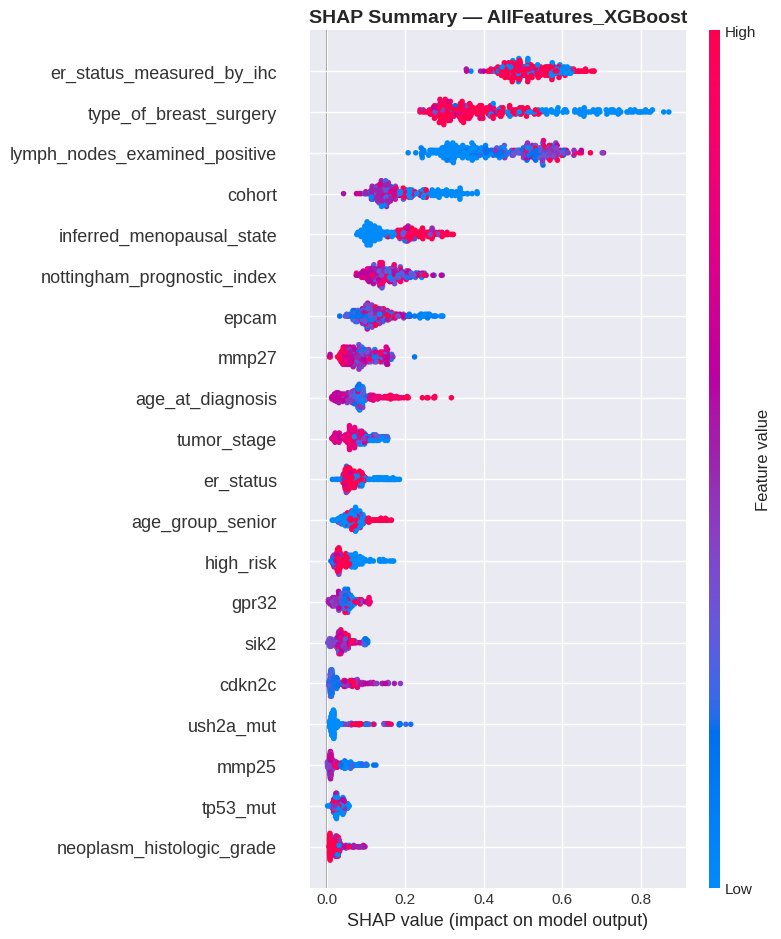

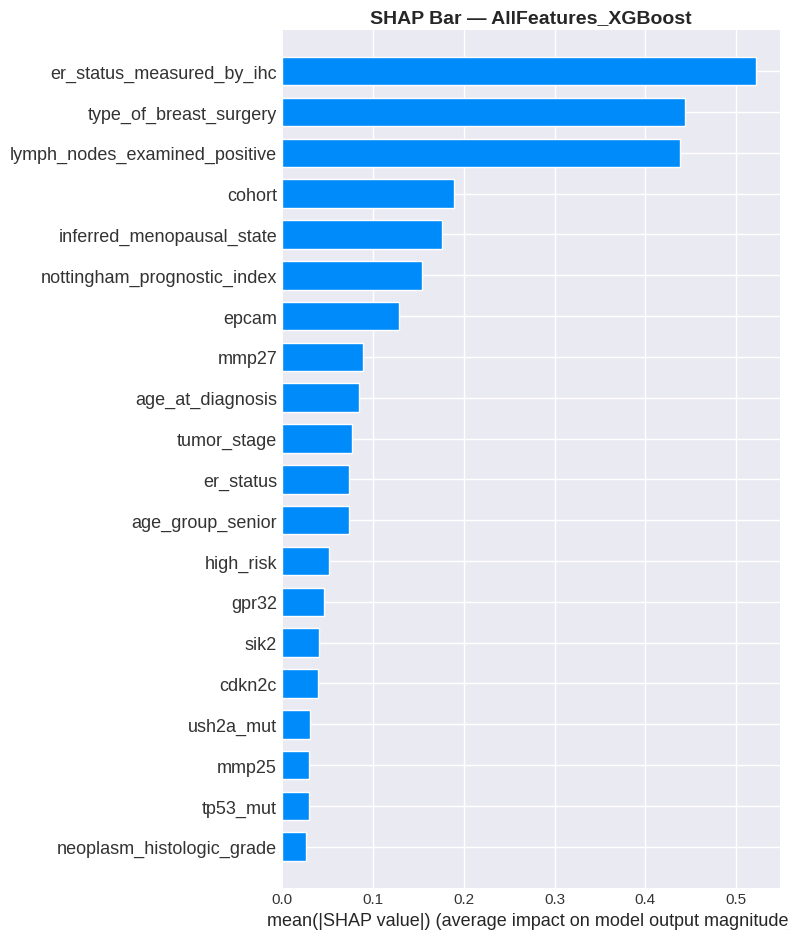

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
    er_status_measured_by_ihc   0.522092
       type_of_breast_surgery   0.443131
lymph_nodes_examined_positive   0.437873
                       cohort   0.188952
    inferred_menopausal_state   0.176392
  nottingham_prognostic_index   0.154652
                        epcam   0.129290
                        mmp27   0.089320
             age_at_diagnosis   0.084765
                  tumor_stage   0.077610
Done: AllFeatures_XGBoost

--- SHAP Analysis: AllFeatures_LightGBM ---
  Feature count: 704, Test samples: 655


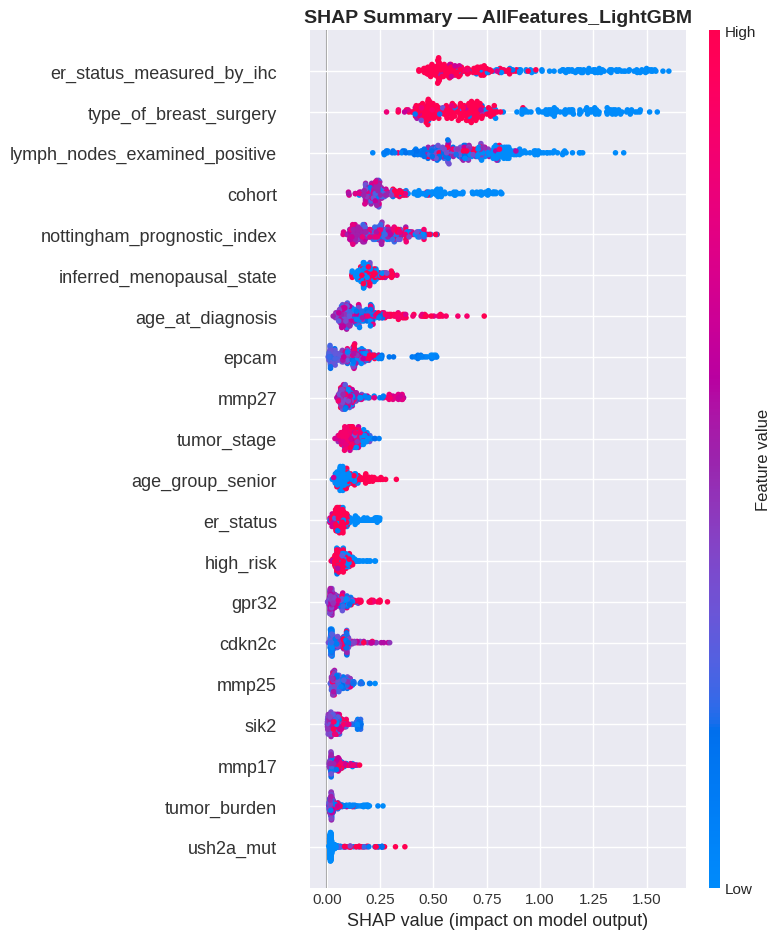

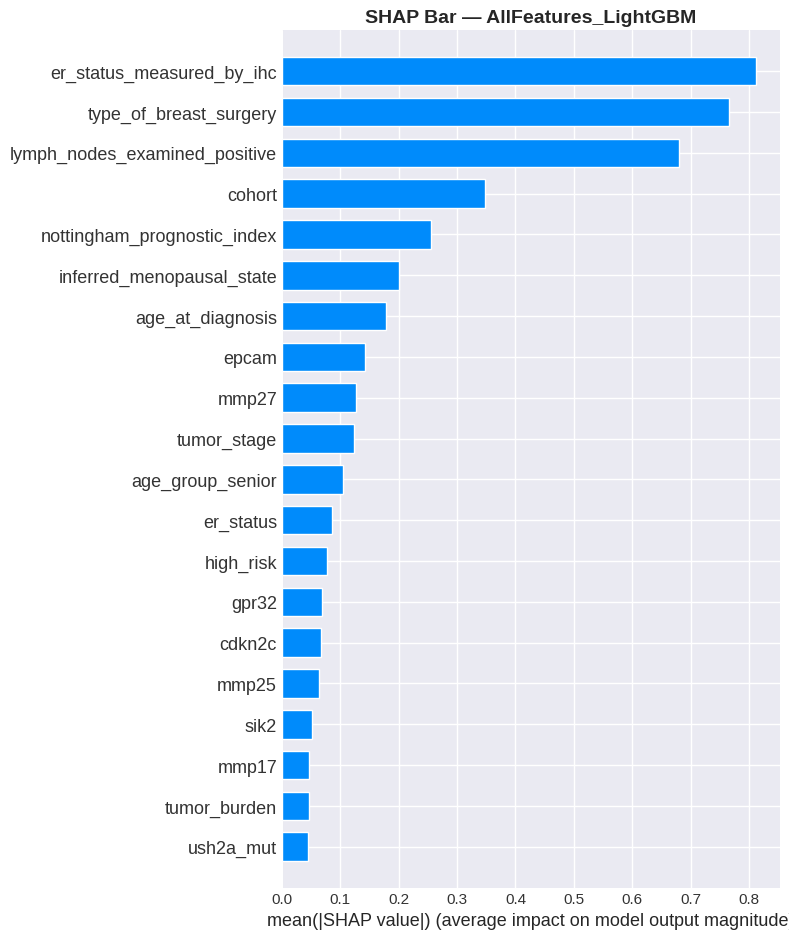

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
    er_status_measured_by_ihc   0.812547
       type_of_breast_surgery   0.766422
lymph_nodes_examined_positive   0.680918
                       cohort   0.347459
  nottingham_prognostic_index   0.255658
    inferred_menopausal_state   0.200056
             age_at_diagnosis   0.178946
                        epcam   0.141562
                        mmp27   0.127445
                  tumor_stage   0.123269
Done: AllFeatures_LightGBM

--- SHAP Analysis: AllFeatures_CatBoost ---
  Feature count: 704, Test samples: 655


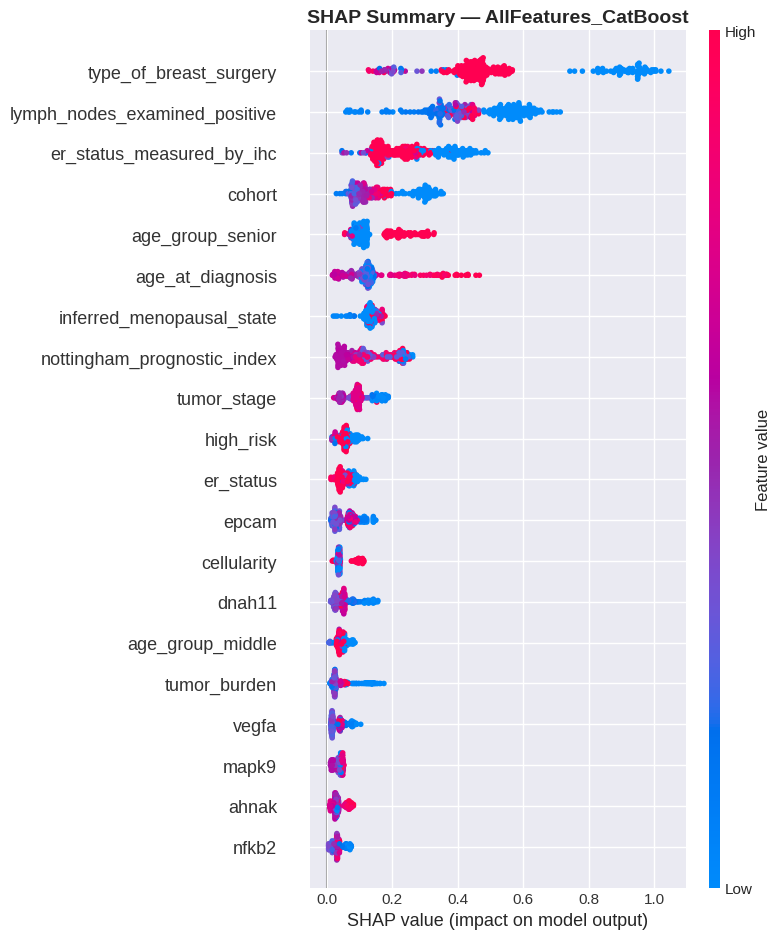

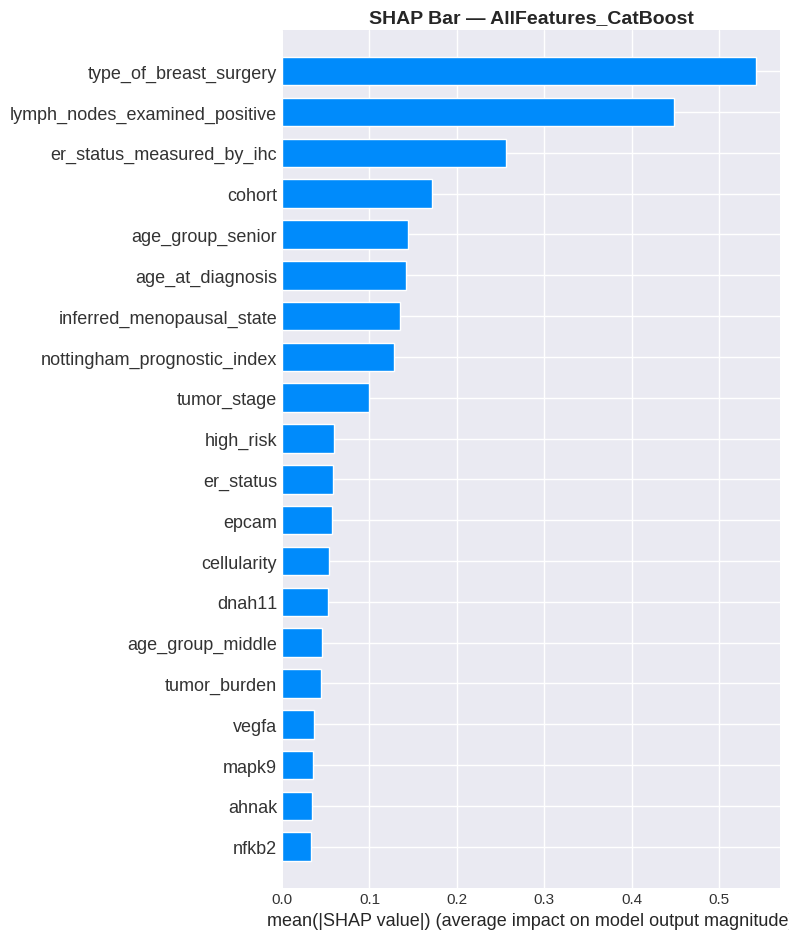

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
       type_of_breast_surgery   0.542241
lymph_nodes_examined_positive   0.448541
    er_status_measured_by_ihc   0.255909
                       cohort   0.172024
             age_group_senior   0.144273
             age_at_diagnosis   0.142081
    inferred_menopausal_state   0.134434
  nottingham_prognostic_index   0.127694
                  tumor_stage   0.099179
                    high_risk   0.059024
Done: AllFeatures_CatBoost

--- SHAP Analysis: AllFeatures_RandomForest ---
  Feature count: 704, Test samples: 655


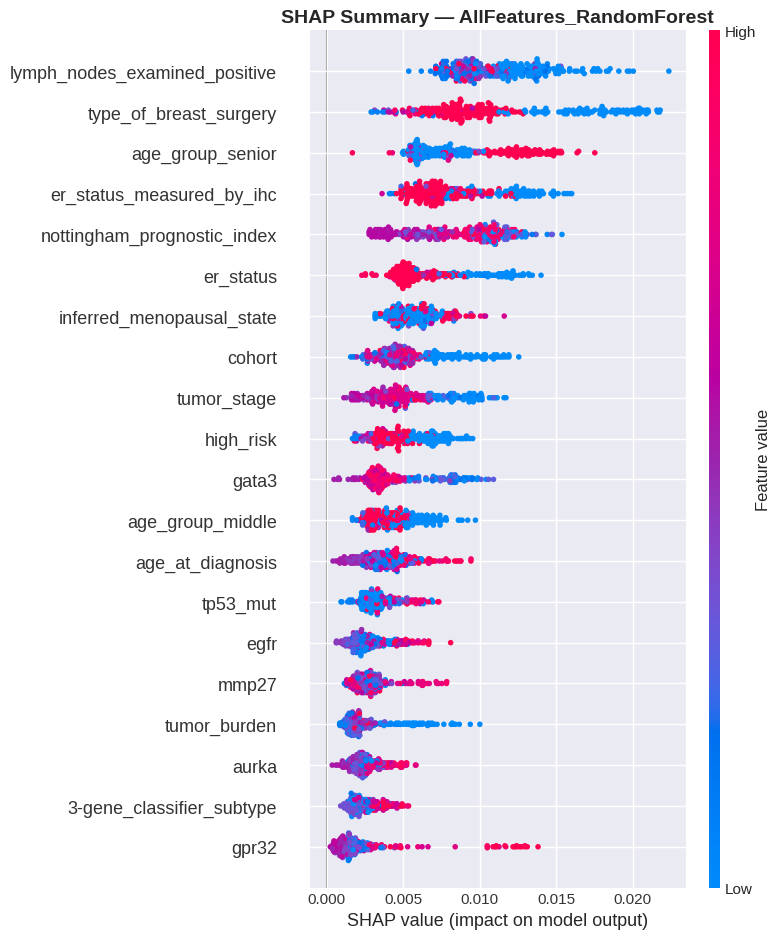

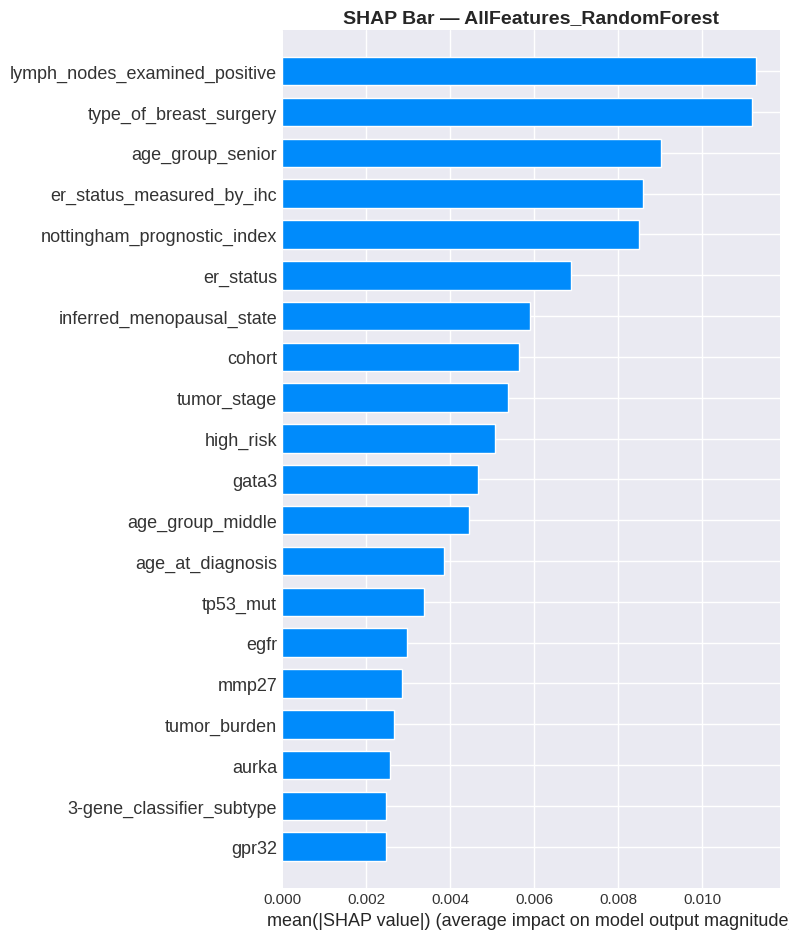

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
lymph_nodes_examined_positive   0.011288
       type_of_breast_surgery   0.011183
             age_group_senior   0.009019
    er_status_measured_by_ihc   0.008586
  nottingham_prognostic_index   0.008504
                    er_status   0.006874
    inferred_menopausal_state   0.005901
                       cohort   0.005645
                  tumor_stage   0.005389
                    high_risk   0.005069
Done: AllFeatures_RandomForest

--- SHAP Analysis: ConsensusFeatures_XGBoost ---
  Feature count: 521, Test samples: 655


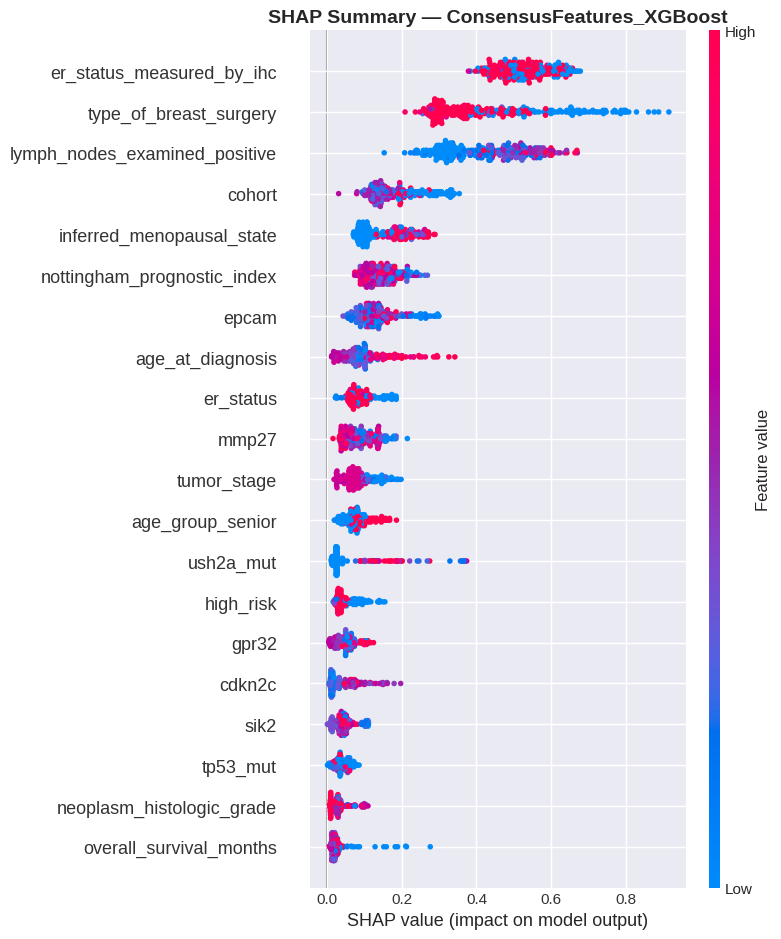

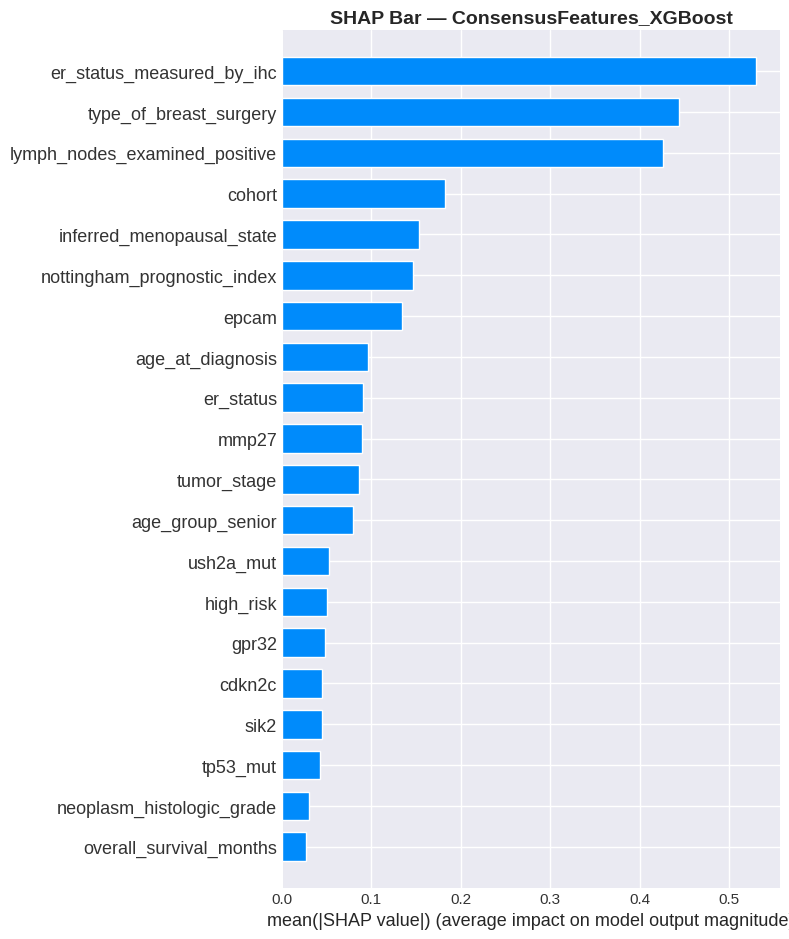

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
    er_status_measured_by_ihc   0.530311
       type_of_breast_surgery   0.444366
lymph_nodes_examined_positive   0.425556
                       cohort   0.182707
    inferred_menopausal_state   0.153421
  nottingham_prognostic_index   0.146992
                        epcam   0.134689
             age_at_diagnosis   0.096705
                    er_status   0.090123
                        mmp27   0.089735
Done: ConsensusFeatures_XGBoost

--- SHAP Analysis: ConsensusFeatures_LightGBM ---
  Feature count: 521, Test samples: 655


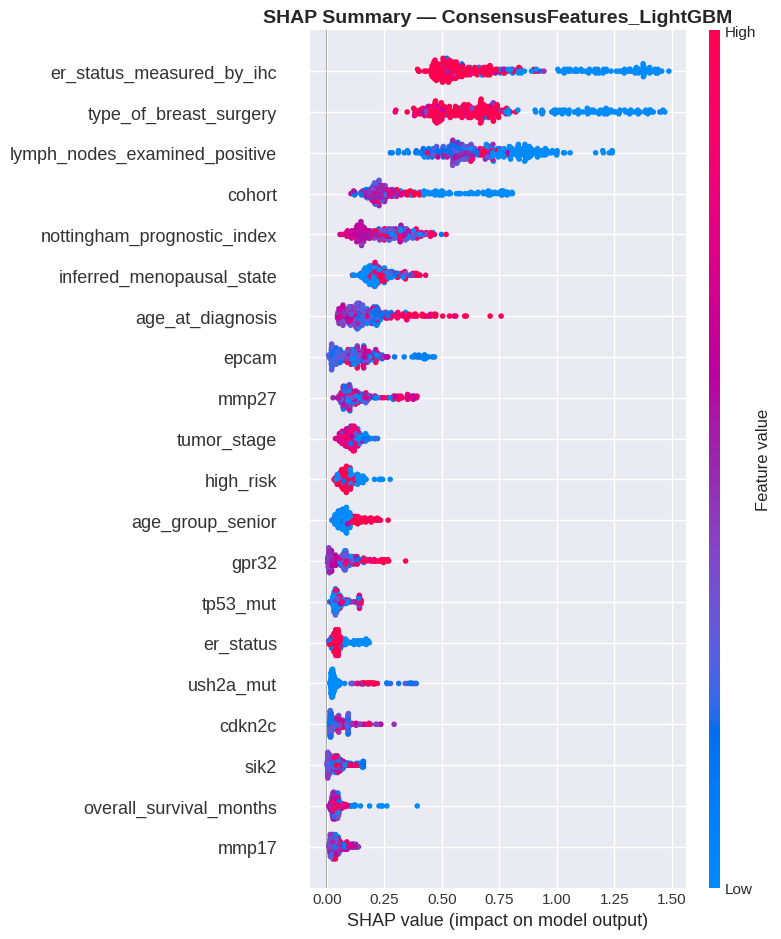

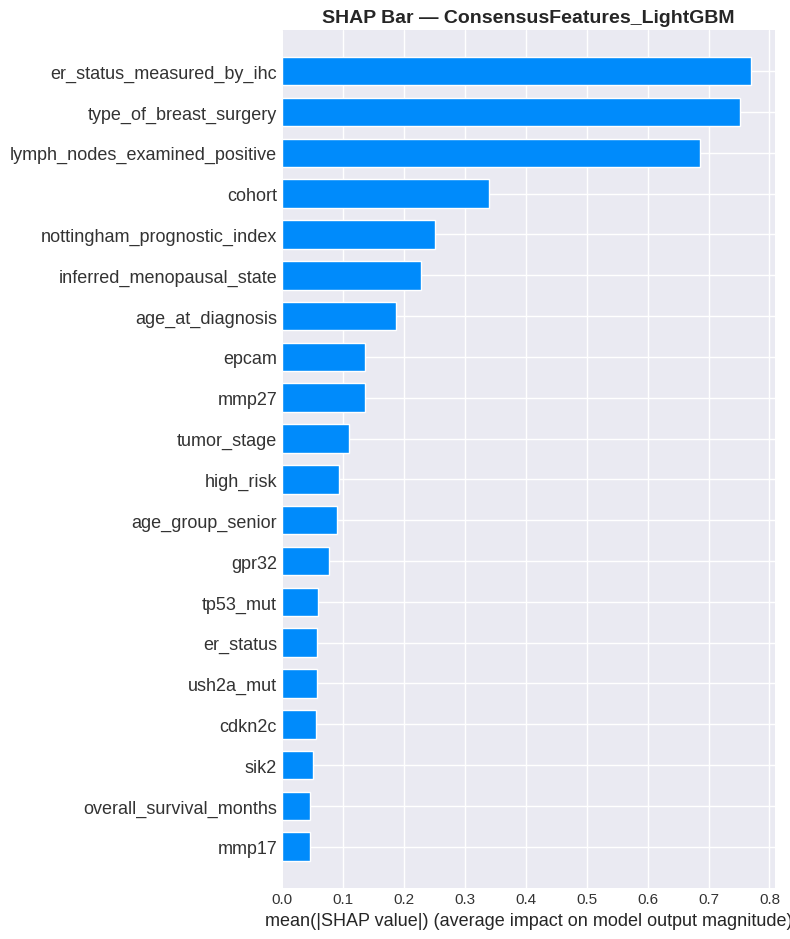

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
    er_status_measured_by_ihc   0.769965
       type_of_breast_surgery   0.752034
lymph_nodes_examined_positive   0.686183
                       cohort   0.339424
  nottingham_prognostic_index   0.250862
    inferred_menopausal_state   0.228191
             age_at_diagnosis   0.187793
                        epcam   0.136423
                        mmp27   0.135513
                  tumor_stage   0.110562
Done: ConsensusFeatures_LightGBM

--- SHAP Analysis: ConsensusFeatures_CatBoost ---
  Feature count: 521, Test samples: 655


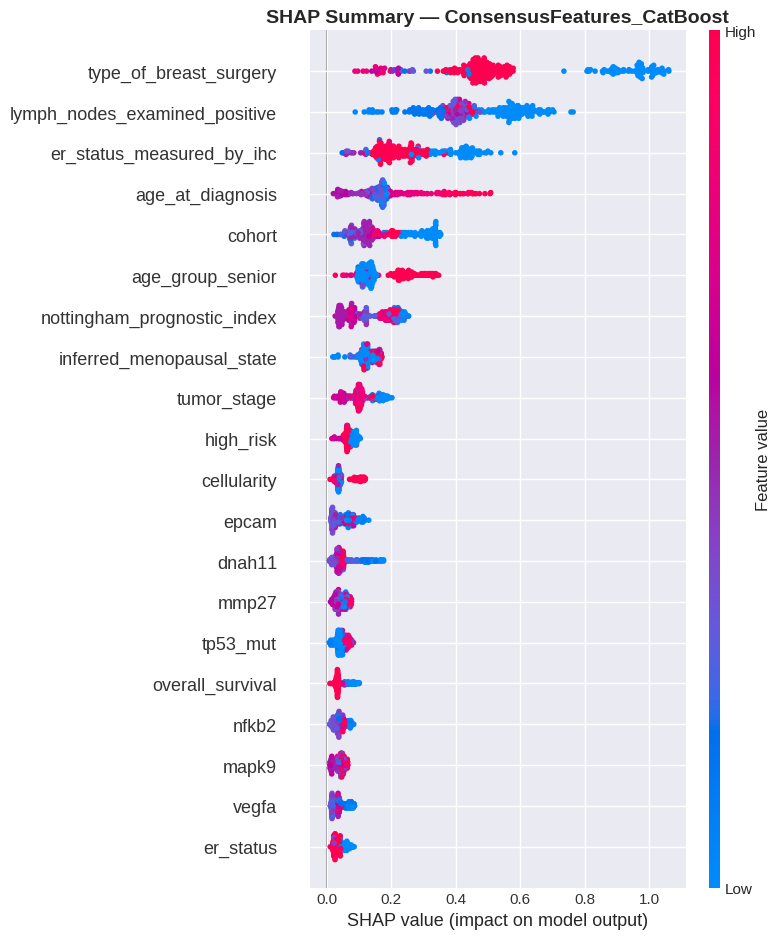

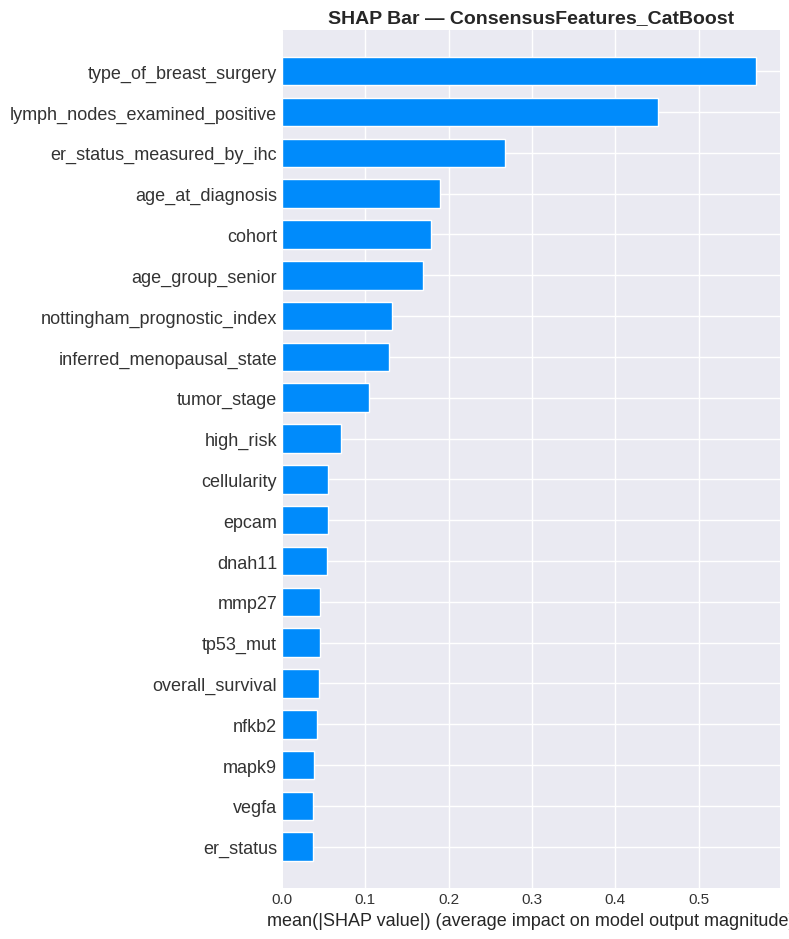

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
       type_of_breast_surgery   0.569072
lymph_nodes_examined_positive   0.451086
    er_status_measured_by_ihc   0.267144
             age_at_diagnosis   0.189903
                       cohort   0.179310
             age_group_senior   0.169202
  nottingham_prognostic_index   0.131634
    inferred_menopausal_state   0.127864
                  tumor_stage   0.104937
                    high_risk   0.071194
Done: ConsensusFeatures_CatBoost

--- SHAP Analysis: ConsensusFeatures_RandomForest ---
  Feature count: 521, Test samples: 655


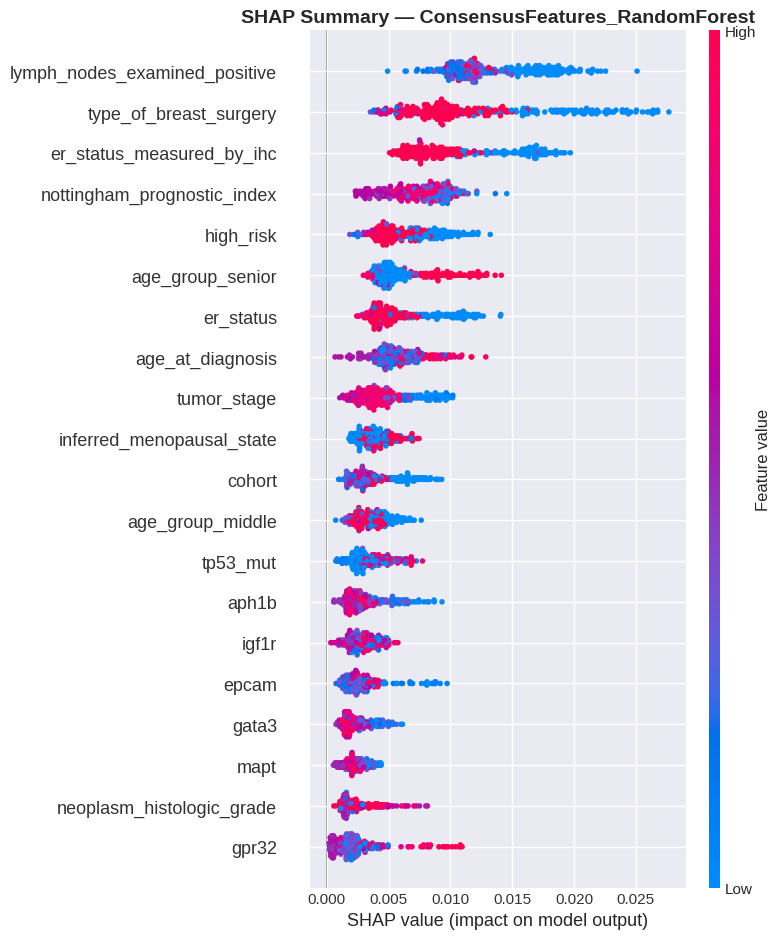

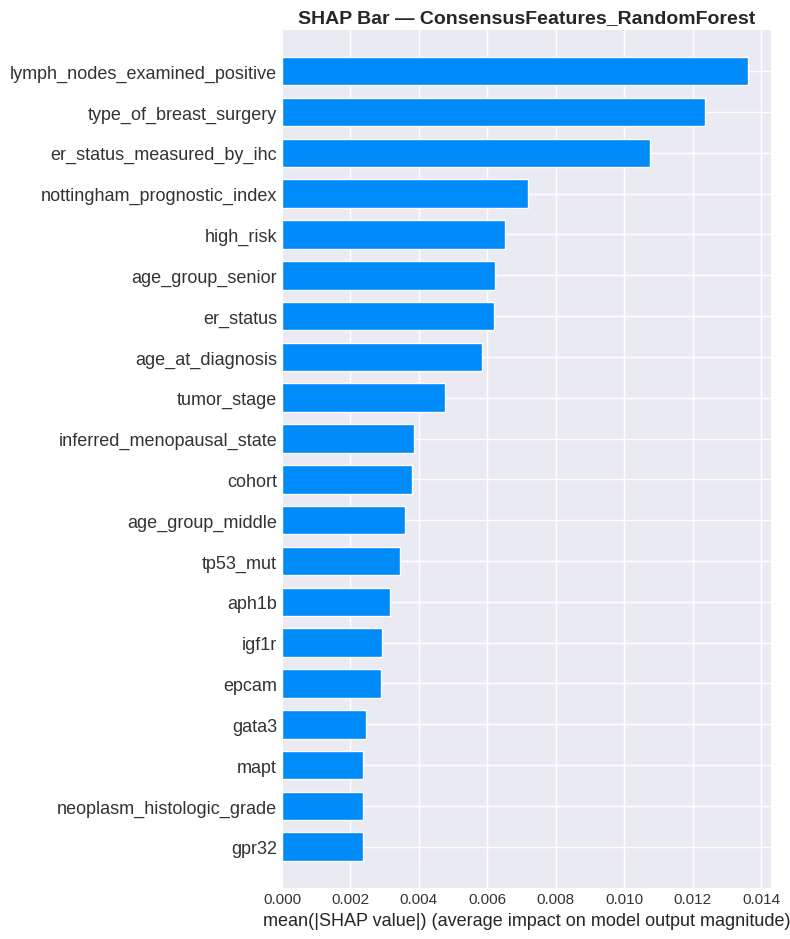

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
lymph_nodes_examined_positive   0.013617
       type_of_breast_surgery   0.012375
    er_status_measured_by_ihc   0.010746
  nottingham_prognostic_index   0.007194
                    high_risk   0.006519
             age_group_senior   0.006216
                    er_status   0.006184
             age_at_diagnosis   0.005844
                  tumor_stage   0.004762
    inferred_menopausal_state   0.003864
Done: ConsensusFeatures_RandomForest

--- SHAP Analysis: Top50Features_XGBoost ---
  Feature count: 50, Test samples: 655


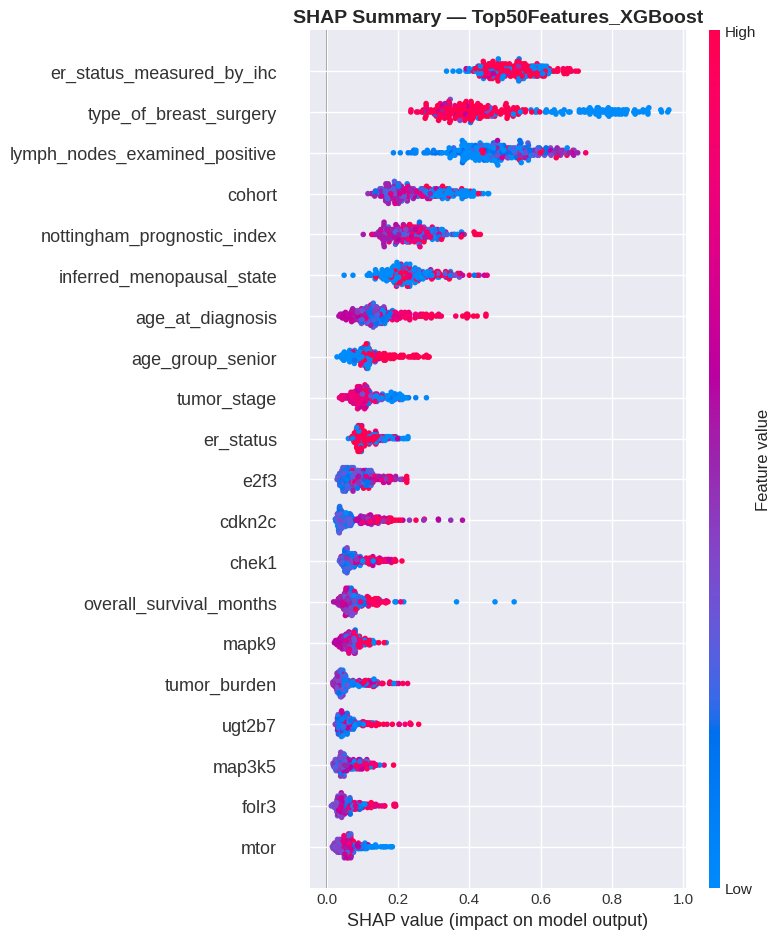

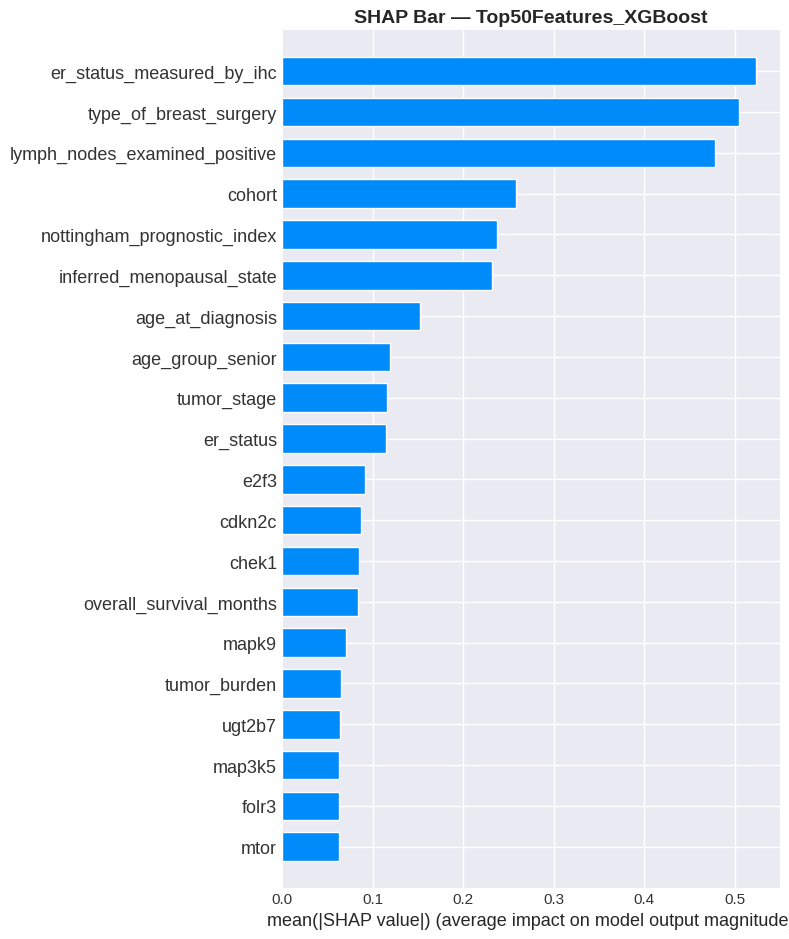

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
    er_status_measured_by_ihc   0.523552
       type_of_breast_surgery   0.504671
lymph_nodes_examined_positive   0.478324
                       cohort   0.257860
  nottingham_prognostic_index   0.237762
    inferred_menopausal_state   0.231476
             age_at_diagnosis   0.152058
             age_group_senior   0.119293
                  tumor_stage   0.116071
                    er_status   0.114460
Done: Top50Features_XGBoost

--- SHAP Analysis: Top50Features_LightGBM ---
  Feature count: 50, Test samples: 655


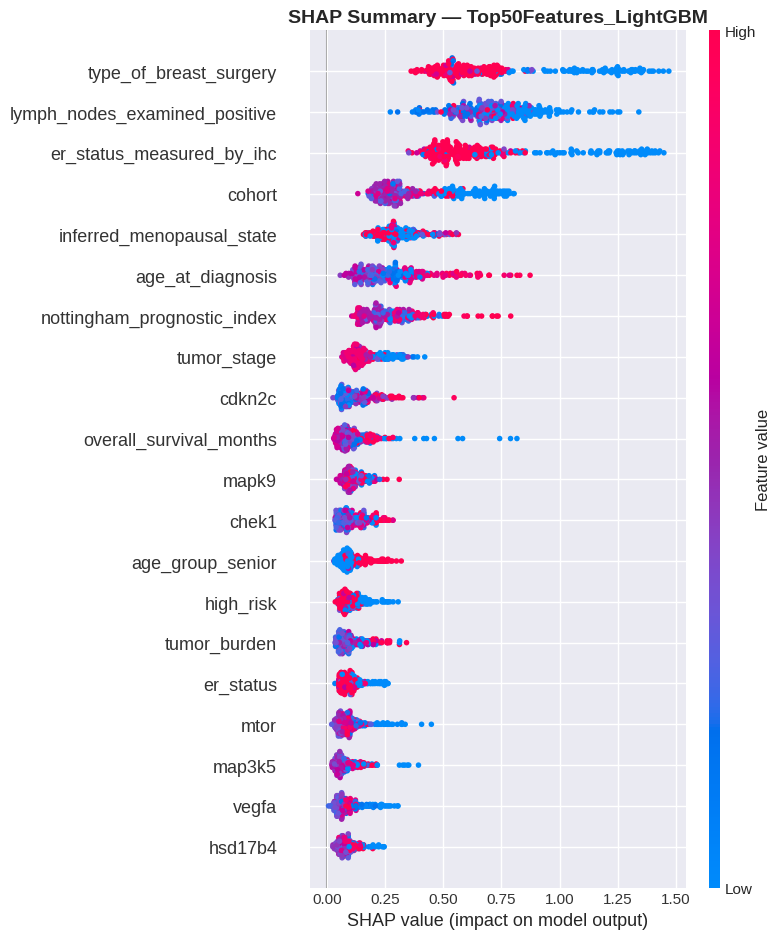

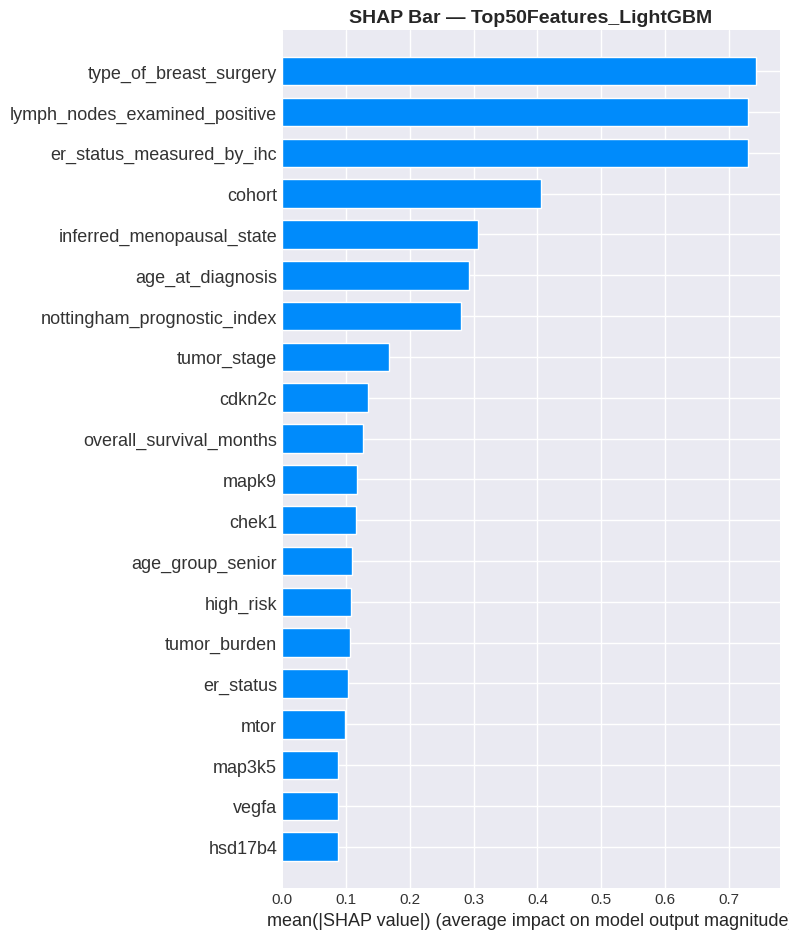

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
       type_of_breast_surgery   0.742615
lymph_nodes_examined_positive   0.729392
    er_status_measured_by_ihc   0.729161
                       cohort   0.405774
    inferred_menopausal_state   0.307013
             age_at_diagnosis   0.292161
  nottingham_prognostic_index   0.280684
                  tumor_stage   0.167722
                       cdkn2c   0.135080
      overall_survival_months   0.126289
Done: Top50Features_LightGBM

--- SHAP Analysis: Top50Features_CatBoost ---
  Feature count: 50, Test samples: 655


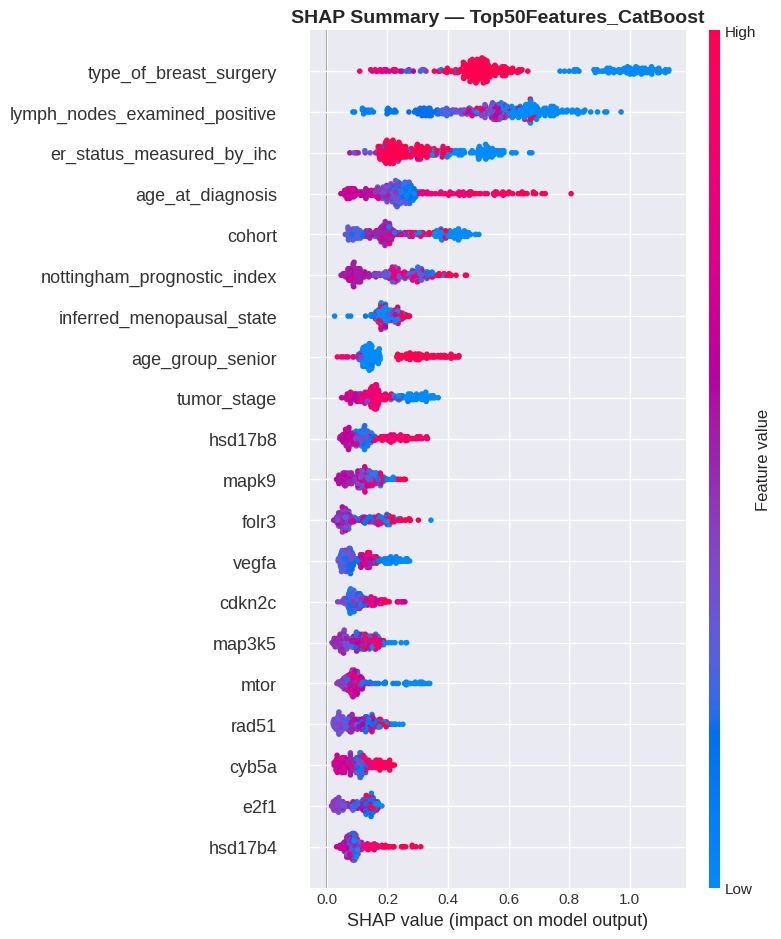

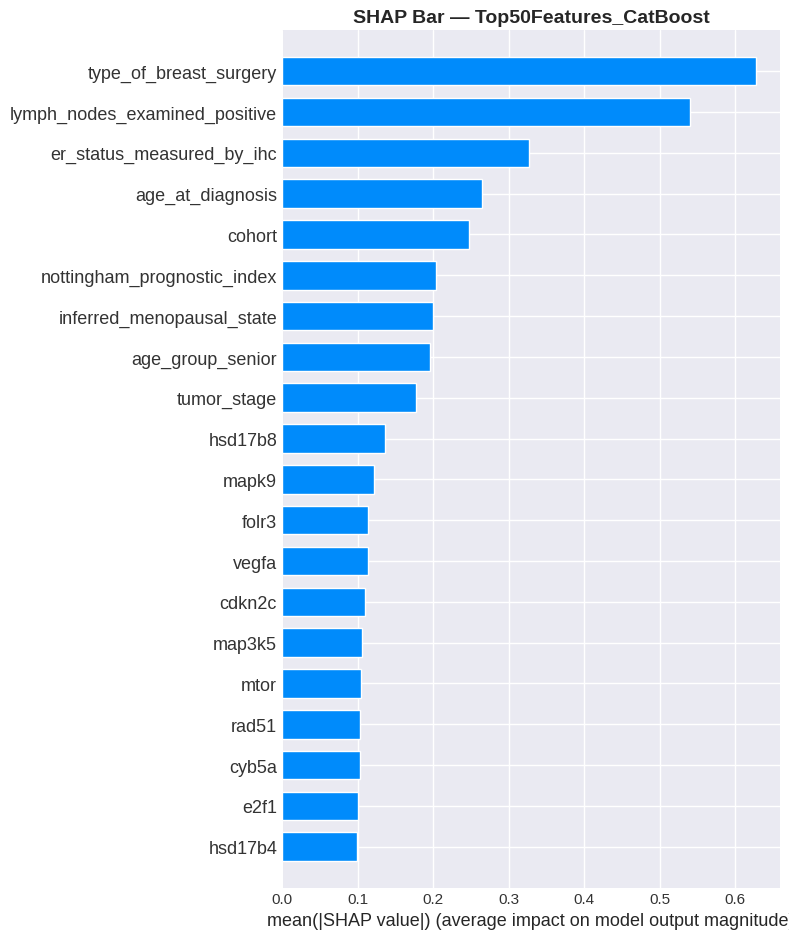

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
       type_of_breast_surgery   0.627742
lymph_nodes_examined_positive   0.539682
    er_status_measured_by_ihc   0.327175
             age_at_diagnosis   0.265311
                       cohort   0.247062
  nottingham_prognostic_index   0.203761
    inferred_menopausal_state   0.199401
             age_group_senior   0.196122
                  tumor_stage   0.177148
                      hsd17b8   0.136563
Done: Top50Features_CatBoost

--- SHAP Analysis: Top50Features_RandomForest ---
  Feature count: 50, Test samples: 655


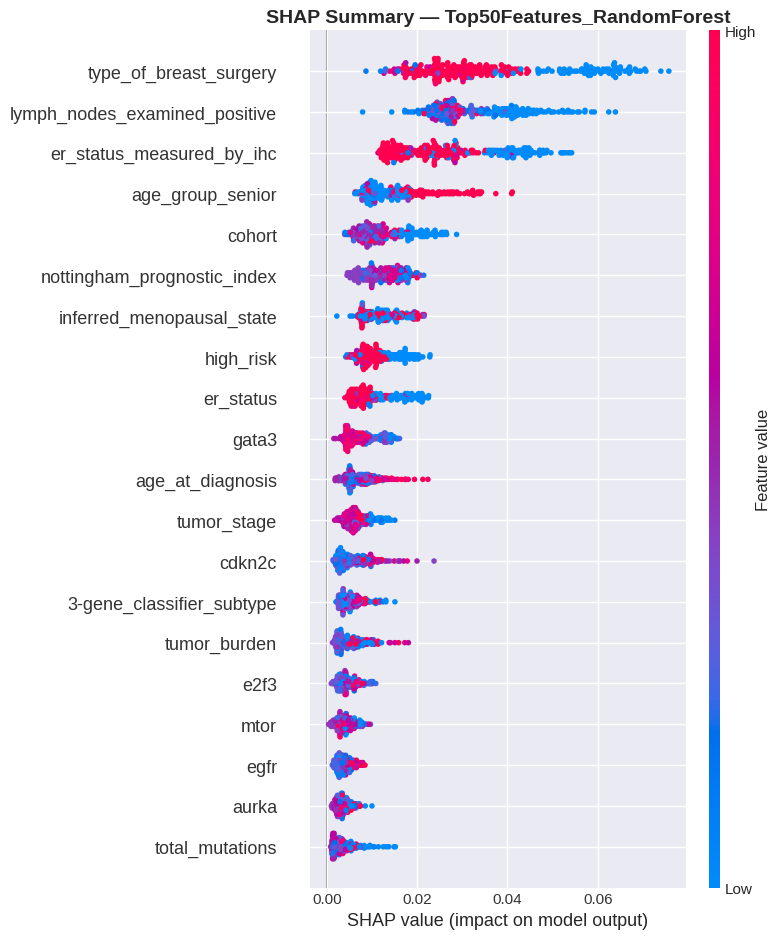

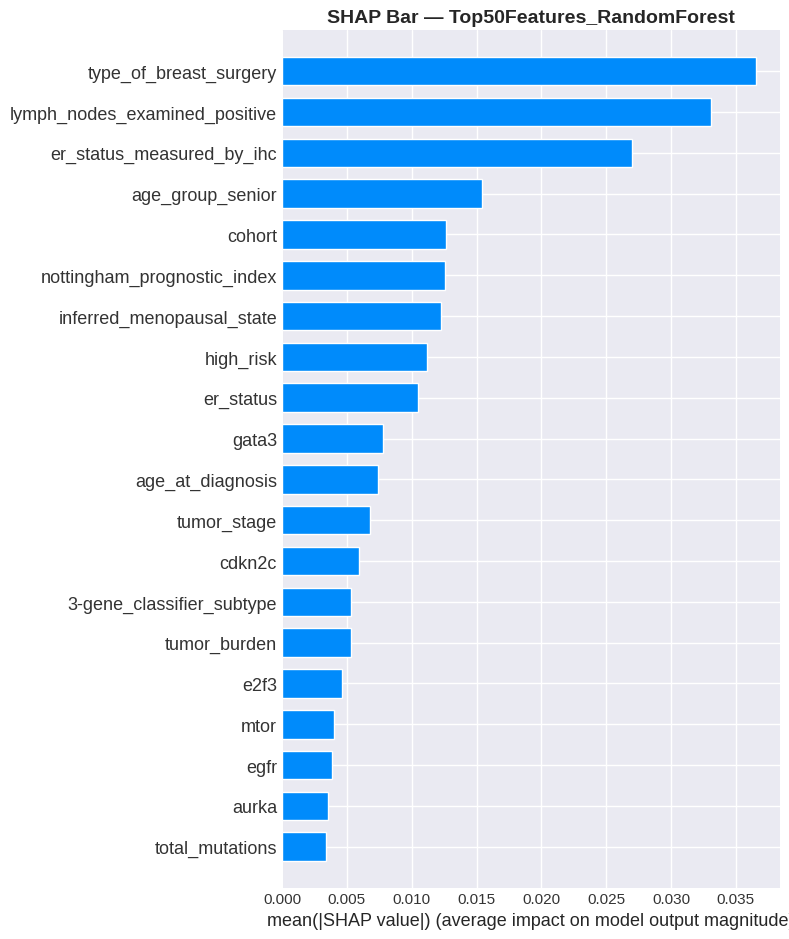

  Top 10 by mean |SHAP|:
                      Feature  Mean_SHAP
       type_of_breast_surgery   0.036570
lymph_nodes_examined_positive   0.033050
    er_status_measured_by_ihc   0.027003
             age_group_senior   0.015429
                       cohort   0.012649
  nottingham_prognostic_index   0.012537
    inferred_menopausal_state   0.012276
                    high_risk   0.011206
                    er_status   0.010515
                        gata3   0.007775
Done: Top50Features_RandomForest


In [ ]:
import shap
import gc

shap.initjs()

def get_shap_explainer(model, X_background, model_name):
    name = model_name.lower()
    try:
        if any(m in name for m in ['xgboost', 'lightgbm', 'catboost', 'randomforest']):
            return shap.TreeExplainer(model), 'tree'
        else:
            background = shap.sample(X_background, min(50, X_background.shape[0]))
            return shap.KernelExplainer(model.predict_proba, background), 'kernel'
    except Exception as e:
        print(f"  TreeExplainer failed ({e}), trying KernelExplainer...")
        try:
            background = shap.sample(X_background, min(50, X_background.shape[0]))
            return shap.KernelExplainer(model.predict_proba, background), 'kernel'
        except Exception as e2:
            print(f"  KernelExplainer also failed ({e2}), skipping.")
            return None, None


def safe_get_shap_values(explainer, X_explain, explainer_type):
    raw = explainer.shap_values(X_explain)

    if isinstance(raw, list):
        stacked = np.stack(raw, axis=0)
        return np.mean(np.abs(stacked), axis=0)

    arr = np.array(raw)

    if arr.ndim == 3:
        if arr.shape[0] == X_explain.shape[0]:
            return np.mean(np.abs(arr), axis=2)
        else:
            return np.mean(np.abs(arr), axis=0)

    return arr


def plot_shap_for_model(model_key, model_data, output_dirs,
                        max_display=20,
                        tree_samples=300,
                        kernel_samples=50): #
    model         = model_data['model']
    X_test        = model_data['X_test']
    feature_names = model_data['feature_names']
    model_name    = model_key.split('_')[-1]

    print(f"\n--- SHAP Analysis: {model_key} ---")
    print(f"  Feature count: {len(feature_names)}, Test samples: {X_test.shape[0]}")

    # Skip KernelExplainer if feature count is too high (will OOM)
    MAX_FEATURES_FOR_KERNEL = 100
    is_tree_model = any(m in model_name.lower()
                        for m in ['xgboost', 'lightgbm', 'catboost', 'randomforest'])

    if not is_tree_model and len(feature_names) > MAX_FEATURES_FOR_KERNEL:
        print(f"Skipping: KernelExplainer on {len(feature_names)} features would OOM.")
        return


    n_explain = tree_samples if is_tree_model else kernel_samples
    n_explain = min(n_explain, X_test.shape[0])

    idx = np.random.choice(X_test.shape[0], n_explain, replace=False)
    X_explain = X_test[idx] if isinstance(X_test, np.ndarray) else X_test.iloc[idx].values
    X_explain_df = pd.DataFrame(X_explain, columns=feature_names)

    try:
        explainer, explainer_type = get_shap_explainer(model, X_explain, model_name)

        if explainer is None:
            print(f"Could not create explainer for {model_key}, skipping.")
            return

        shap_values = safe_get_shap_values(explainer, X_explain, explainer_type)

        if shap_values.shape != (n_explain, len(feature_names)):
            print(f"Shape mismatch {shap_values.shape}, skipping plots.")
            return

        # Beeswarm plot
        fig1, ax1 = plt.subplots(figsize=(12, 8))
        plt.sca(ax1)
        shap.summary_plot(shap_values, X_explain_df,
                          feature_names=feature_names,
                          max_display=max_display, show=False)
        ax1.set_title(f'SHAP Summary — {model_key}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(output_dirs['plots'] / f'{model_key}_shap_summary.png', dpi=900, bbox_inches='tight')
        plt.savefig(output_dirs['plots'] / f'{model_key}_shap_summary.svg', bbox_inches='tight')
        plt.show()
        plt.close(fig1)

        # Bar plot
        fig2, ax2 = plt.subplots(figsize=(10, 7))
        plt.sca(ax2)
        shap.summary_plot(shap_values, X_explain_df,
                          feature_names=feature_names,
                          plot_type='bar',
                          max_display=max_display, show=False)
        ax2.set_title(f'SHAP Bar — {model_key}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(output_dirs['plots'] / f'{model_key}_shap_bar.png', dpi=900, bbox_inches='tight')
        plt.savefig(output_dirs['plots'] / f'{model_key}_shap_bar.svg', bbox_inches='tight')
        plt.show()
        plt.close(fig2)

        mean_shap = pd.DataFrame({
            'Feature': feature_names,
            'Mean_SHAP': np.abs(shap_values).mean(axis=0)
        }).sort_values('Mean_SHAP', ascending=False)

        mean_shap.to_csv(output_dirs['metrics'] / f'{model_key}_shap_ranking.csv', index=False)

        print(f"  Top 10 by mean |SHAP|:")
        print(mean_shap.head(10).to_string(index=False))
        print(f"Done: {model_key}")

    except Exception as e:
        print(f"SHAP failed for {model_key}: {e}")

    finally:
        gc.collect()
        plt.close('all')



for model_key, model_data in trained_models.items():
    plot_shap_for_model(model_key, model_data, output_dirs)

In [ ]:
!zip -qr9 outputs.zip outputs/